# TP1 – Aprendizaje Automático: deserción universitaria
**Grupo:** Martín López y Diego Alejandro Rojas Betancourt — Comisión 2

Notebook unificada del informe (corre de punta a punta a partir del CSV original). Estructura:

1. Carga, calidad de datos y análisis exploratorio
2. Preprocesamiento para la tarea multiclase
3. Variables derivadas y **tarea binaria Graduado vs. Desertor** (sin "En curso"): Valor de Información; regresión logística, SVM,
   árbol de decisión, *Voting*; curvas de complejidad; aplicación del modelo a los estudiantes "En curso"; **modelo logístico explicativo**
   con índice de rendimiento académico, IC 95 %, VIF, importancia por permutación y dependencia parcial por grupos
4. **Clasificación multiclase** (Desertor / En Curso / Graduado): K-NN, árbol, Random Forest (bagging), AdaBoost y XGBoost (boosting)
5. Importancia de atributos (individual y por grupos de variables correlacionadas) y dependencia parcial del mejor modelo multiclase
6. Exportación de resultados

Todas las semillas se fijan en `SEED = 42` para que los resultados sean reproducibles.

In [4]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     validation_curve)
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (VotingClassifier, RandomForestClassifier, AdaBoostClassifier)
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
N_JOBS = -1
# busca el CSV en la carpeta dataset/ del repositorio, junto a la notebook o en el material de la cátedra
DATA = next(p for p in [Path("../dataset/dataset_TP1_2026.csv"), Path("dataset/dataset_TP1_2026.csv"), Path("dataset_TP1_2026.csv"),
                        Path("../Material para el TP1-20261008/dataset_TP1_2026.csv")] if p.exists())
FIG = Path("../images/informe") if Path("../images").exists() else Path("figuras")
FIG.mkdir(parents=True, exist_ok=True)
RES = {}  # resultados que se usan en el informe

# Estilo de gráficos (paleta categórica fija; texto en tinta neutra)
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA, C_GREEN = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
CLASS_COLORS = {"Desertor": C_ORANGE, "En Curso": C_AQUA, "Graduado": C_BLUE}
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b2a", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2,
})
def savefig(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

## 1. Datos y análisis exploratorio

In [3]:
df = pd.read_csv(DATA, encoding="utf-8-sig")
print(df.shape)
print("Faltantes:", int(df.isna().sum().sum()), "| Filas duplicadas:", int(df.duplicated().sum()))
df.head()

(50000, 28)
Faltantes: 0 | Filas duplicadas: 313


,Estudios_máximos_antes_de_la_inscripción,estado_civil,modo_aplicacion,sexo,desplazado,target,Carrera,Asistencia_diurna/nocturna,Cualificación_promedio_de_estudios_previos,Puntaje_en_examen_de_ingreso,...,Unidades_curriculares_1er_semestre_(aprobadas),Nota_promedio_en_el_1er_semestre,Unidades_curriculares_2do_semestre_(inscrito),Cantidad_de_evaluaciones_en_el_2do_semestre_,Unidades_curriculares_2do_semestre_(aprobadas),Nota_promedio_en_el_2do_semestre,Demanda_Cog_Padre,Demanda_Cog_Madre,Ingresos_Padre,Ingresos_Madre
0,Educación Secundaria,Soltero,Acceso General,Femenino,Sí,Graduado,Turismo,Diurna,65,61,...,6,63,6,8,5,69,Muy baja demanda cognitiva,Muy baja demanda cognitiva,Bajos ingresos,Bajos ingresos
1,Educación Secundaria,Soltero,Acceso por Normativa Específica,Femenino,No,Desertor,Enfermería,Diurna,67,58,...,0,0,7,7,0,0,Muy baja demanda cognitiva,Muy baja demanda cognitiva,Bajos ingresos,Bajos ingresos
2,Educación Secundaria,Soltero,Acceso General,Femenino,Sí,En Curso,Gestión,Diurna,64,62,...,3,53,5,10,2,52,Muy baja demanda cognitiva,Demanda cognitiva media,Bajos ingresos,Ingresos medios
3,Educación Secundaria,Soltero,Acceso General,Femenino,Sí,En Curso,Enfermería,Diurna,67,54,...,5,63,7,8,3,58,Demanda cognitiva media,Demanda cognitiva media,Ingresos medios,Ingresos medios
4,Educación Secundaria,Soltero,Acceso General,Femenino,Sí,En Curso,Publicidad y Marketing,Diurna,68,62,...,6,62,6,9,6,65,Muy alta demanda cognitiva,Muy baja demanda cognitiva,Altos ingresos,Bajos ingresos


Las filas duplicadas son registros idénticos en las 28 columnas. Provienen de la aumentación sintética del dataset de Kaggle
(no hay un identificador de estudiante), por lo que se eliminan para evitar que un mismo registro aparezca a la vez en entrenamiento y prueba.

In [5]:
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
RES["n_original"] = n0; RES["n_dup"] = n0 - len(df); RES["n"] = len(df)
print(len(df))

49687


In [6]:
num_cols = df.select_dtypes("number").columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols + ["target"]]
print(len(num_cols), "numéricas |", len(cat_cols), "categóricas")
df[num_cols].describe().T.round(1)

11 numéricas | 16 categóricas


,count,mean,std,min,25%,50%,75%,max
Cualificación_promedio_de_estudios_previos,49687.0,66.2,5.5,48.0,62.0,67.0,70.0,95.0
Puntaje_en_examen_de_ingreso,49687.0,62.7,6.3,48.0,59.0,62.0,66.0,95.0
Edad_al_momento_de_la_inscripción,49687.0,22.3,6.9,17.0,18.0,19.0,23.0,70.0
Unidades_curriculares_1er_semestre_(inscrito),49687.0,5.9,1.7,0.0,5.0,6.0,6.0,26.0
Cantidad_de_evaluaciones_en_el_1er_semestre,49687.0,7.4,3.5,0.0,6.0,7.0,9.0,45.0
Unidades_curriculares_1er_semestre_(aprobadas),49687.0,4.2,2.7,0.0,2.0,5.0,6.0,26.0
Nota_promedio_en_el_1er_semestre,49687.0,50.1,26.2,0.0,53.0,61.0,67.0,94.0
Unidades_curriculares_2do_semestre_(inscrito),49687.0,5.9,1.6,0.0,5.0,6.0,6.0,21.0
Cantidad_de_evaluaciones_en_el_2do_semestre_,49687.0,7.3,3.5,0.0,6.0,8.0,9.0,33.0
Unidades_curriculares_2do_semestre_(aprobadas),49687.0,4.0,2.8,0.0,1.0,5.0,6.0,19.0


### Redundancia entre variables socioeconómicas
Según el diccionario, `Demanda_Cog_*` e `Ingresos_*` se derivan **con la misma regla** a partir del grupo ISCO-08 de la ocupación.
Verificamos si la relación es 1 a 1:

In [7]:
for p in ["Padre", "Madre"]:
    ct = pd.crosstab(df[f"Demanda_Cog_{p}"], df[f"Ingresos_{p}"])
    print(p, "-> categorías de ingreso por categoría de demanda:", (ct > 0).sum(axis=1).tolist())

Padre -> categorías de ingreso por categoría de demanda: [1, 1, 1, 1, 1]
Madre -> categorías de ingreso por categoría de demanda: [1, 1, 1, 1, 1]


Cada nivel de demanda cognitiva corresponde a exactamente un nivel de ingresos: son la **misma variable con otra etiqueta**.
Se eliminan `Ingresos_Padre` e `Ingresos_Madre` (información duplicada; en modelos lineales generaría colinealidad perfecta).

In [8]:
df = df.drop(columns=["Ingresos_Padre", "Ingresos_Madre"])
cat_cols = [c for c in cat_cols if not c.startswith("Ingresos_")]

### Balance de clases

target
Graduado    23521
Desertor    16404
En Curso     9762
Name: count, dtype: int64
target
Graduado    0.473
Desertor    0.330
En Curso    0.196
Name: count, dtype: float64


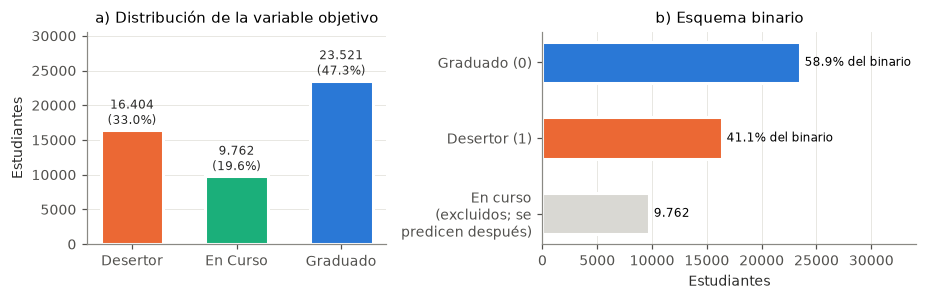

In [9]:
vc = df["target"].value_counts()
RES["clases"] = (vc / len(df)).round(4).to_dict()
print(vc, (vc / len(df)).round(3), sep="\n")

order = ["Desertor", "En Curso", "Graduado"]
fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.8), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
vals = [vc[c] for c in order]
ax.bar(order, vals, color=[CLASS_COLORS[c] for c in order], width=0.6, edgecolor="white", linewidth=2)
for i, v in enumerate(vals):
    ax.text(i, v + 300, f"{v:,}\n({v/len(df):.1%})".replace(",", "."), ha="center", va="bottom", fontsize=8, color="#2b2b2a")
ax.set_ylim(0, max(vals) * 1.3); ax.set_ylabel("Estudiantes"); ax.set_title("a) Distribución de la variable objetivo")
ax.grid(axis="x", visible=False)
# Esquema binario: Graduado vs. Desertor (los "En curso" se excluyen del entrenamiento)
ax = axes[1]
bvals = [(df.target == "Graduado").sum(), (df.target == "Desertor").sum(), (df.target == "En Curso").sum()]
labs = ["Graduado (0)", "Desertor (1)", "En curso\n(excluidos; se\npredicen después)"]
nb = bvals[0] + bvals[1]
ax.barh(labs[::-1], bvals[::-1], color=["#d9d8d3", C_ORANGE, C_BLUE], height=0.55, edgecolor="white", linewidth=2)
for i, v in enumerate(bvals[::-1]):
    ax.text(v + 400, i, (f"{v/nb:.1%} del binario" if i > 0 else f"{v:,}".replace(",", ".")), va="center", fontsize=8)
ax.set_xlim(0, max(bvals) * 1.45); ax.set_title("b) Esquema binario"); ax.set_xlabel("Estudiantes"); ax.grid(axis="y", visible=False)
plt.tight_layout(); savefig("fig1_clases")

El desbalance es moderado (≈ 59/41 en el esquema binario Graduado/Desertor; la clase minoritaria multiclase, *En Curso*, es ≈ 20 %).
Estrategia: (i) particiones estratificadas y (ii) F1-macro (y AUC) para seleccionar y comparar modelos; en la multiclase se explora además
`class_weight` como hiper-parámetro. No se usa sobre-muestreo.

### Relación de los atributos con la deserción

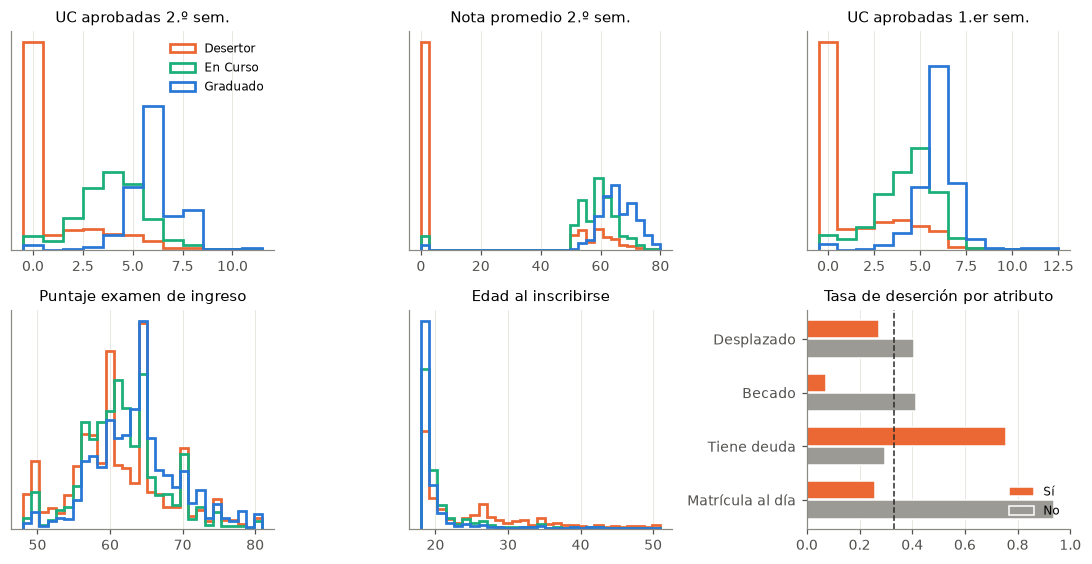

In [10]:
df["_desertor"] = (df.target == "Desertor").astype(int)
fig, axes = plt.subplots(2, 3, figsize=(10, 5.2))
plot_num = ["Unidades_curriculares_2do_semestre_(aprobadas)", "Nota_promedio_en_el_2do_semestre",
            "Unidades_curriculares_1er_semestre_(aprobadas)", "Puntaje_en_examen_de_ingreso",
            "Edad_al_momento_de_la_inscripción"]
nice = {"Unidades_curriculares_2do_semestre_(aprobadas)": "UC aprobadas 2.º sem.",
        "Nota_promedio_en_el_2do_semestre": "Nota promedio 2.º sem.",
        "Unidades_curriculares_1er_semestre_(aprobadas)": "UC aprobadas 1.er sem.",
        "Puntaje_en_examen_de_ingreso": "Puntaje examen de ingreso",
        "Edad_al_momento_de_la_inscripción": "Edad al inscribirse"}
for ax, c in zip(axes.flat, plot_num):
    lo, hi = df[c].quantile([0.005, 0.995])
    bins = np.linspace(lo, hi, 30) if df[c].nunique() > 30 else np.arange(lo - .5, hi + 1.5, 1)
    for k in order:
        ax.hist(df.loc[df.target == k, c], bins=bins, density=True, histtype="step", lw=1.8, color=CLASS_COLORS[k], label=k)
    ax.set_title(nice[c]); ax.set_yticks([])
axes.flat[0].legend(fontsize=8)
# tasa de deserción por categorías binarias
ax = axes.flat[5]
bin_vars = {"Pago_de_matrícula_al_día": "Matrícula al día", "Tiene_deuda": "Tiene deuda",
            "Poseedor_de_Beca": "Becado", "desplazado": "Desplazado"}
rows = []
for c, lab in bin_vars.items():
    r = df.groupby(c)["_desertor"].mean()
    rows.append((lab, r.get("Sí"), r.get("No")))
y = np.arange(len(rows))
ax.barh(y + 0.18, [r[1] for r in rows], height=0.34, color=C_ORANGE, label="Sí", edgecolor="white")
ax.barh(y - 0.18, [r[2] for r in rows], height=0.34, color="#9b9a95", label="No", edgecolor="white")
ax.set_yticks(y, [r[0] for r in rows]); ax.set_xlim(0, 1); ax.set_title("Tasa de deserción por atributo")
ax.axvline(df._desertor.mean(), color="#2b2b2a", lw=1, ls="--"); ax.legend(loc="lower right", fontsize=8); ax.grid(axis="y", visible=False)
plt.tight_layout(); savefig("fig2_eda")
RES["tasa_desercion_matricula_no"] = float(df.loc[df["Pago_de_matrícula_al_día"] == "No", "_desertor"].mean())
RES["tasa_desercion_matricula_si"] = float(df.loc[df["Pago_de_matrícula_al_día"] == "Sí", "_desertor"].mean())
RES["tasa_desercion_beca_si"] = float(df.loc[df["Poseedor_de_Beca"] == "Sí", "_desertor"].mean())
RES["tasa_desercion_beca_no"] = float(df.loc[df["Poseedor_de_Beca"] == "No", "_desertor"].mean())

In [11]:
tasa_carrera = df.groupby("Carrera")["_desertor"].mean().sort_values()
RES["tasa_carrera"] = tasa_carrera.round(3).to_dict()
tasa_carrera.round(3)

Carrera
Enfermería                                     0.136
Diseño de Comunicación                         0.210
Periodismo y Comunicación                      0.222
Servicio Social                                0.248
Enfermería Veterinaria                         0.322
Publicidad y Marketing                         0.339
Educación Básica                               0.365
Turismo                                        0.371
Higiene Bucodental                             0.373
Gestión                                        0.424
Agronomía                                      0.524
Equinocultura                                  0.546
Ingeniería Informática                         0.598
Animación y Diseño Multimedia                  0.705
Tecnología en Producción de Biocombustibles    0.745
Name: _desertor, dtype: float64

Correlación entre variables numéricas (las de rendimiento por semestre están muy correlacionadas entre sí):

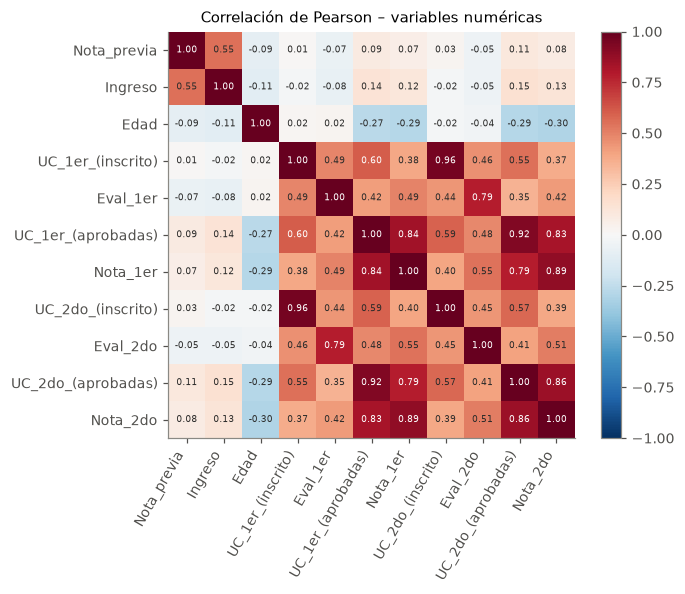

In [12]:
corr = df[num_cols].corr()
short = {c: c.replace("Unidades_curriculares_", "UC_").replace("Cantidad_de_evaluaciones_en_el_", "Eval_")
         .replace("Nota_promedio_en_el_", "Nota_").replace("_semestre", "").replace("Cualificación_promedio_de_estudios_previos", "Nota_previa")
         .replace("Puntaje_en_examen_de_ingreso", "Ingreso").replace("Edad_al_momento_de_la_inscripción", "Edad").rstrip("_") for c in num_cols}
fig, ax = plt.subplots(figsize=(6, 4.8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), [short[c] for c in num_cols], rotation=60, ha="right")
ax.set_yticks(range(len(num_cols)), [short[c] for c in num_cols]); ax.grid(False)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(corr.iloc[i, j]) > .6 else "#2b2b2a")
plt.colorbar(im, fraction=0.04); ax.set_title("Correlación de Pearson – variables numéricas")
savefig("fig_corr")
RES["corr_aprob_1_2"] = float(corr.loc["Unidades_curriculares_1er_semestre_(aprobadas)", "Unidades_curriculares_2do_semestre_(aprobadas)"])
df = df.drop(columns="_desertor")

## 2. Preprocesamiento (tarea multiclase)

* **Numéricas** (11): estandarización (`StandardScaler`), necesaria para LR, SVM y K-NN (modelos basados en distancias/márgenes o con regularización).
* **Ordinales** (`Demanda_Cog_Padre/Madre`, `Estudios_máximos_antes_de_la_inscripción`): codificación ordinal + estandarización.
* **Nominales** (resto): *one-hot*.

El preprocesamiento va **dentro de un `Pipeline`** para que se ajuste sólo con los datos de entrenamiento de cada fold (sin fuga de información).

In [13]:
ord_levels = {
    "Demanda_Cog_Padre": ["Muy baja demanda cognitiva", "Demanda cognitiva baja", "Demanda cognitiva media", "Alta demanda cognitiva", "Muy alta demanda cognitiva"],
    "Demanda_Cog_Madre": ["Muy baja demanda cognitiva", "Demanda cognitiva baja", "Demanda cognitiva media", "Alta demanda cognitiva", "Muy alta demanda cognitiva"],
    "Estudios_máximos_antes_de_la_inscripción": ["Otros / No completado", "Educación Básica", "Educación Secundaria", "Superior - Pregrado", "Superior - Posgrado"],
}
ord_cols = list(ord_levels)
nom_cols = [c for c in cat_cols if c not in ord_cols]

def make_prep():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("ord", Pipeline([("oe", OrdinalEncoder(categories=[ord_levels[c] for c in ord_cols])), ("sc", StandardScaler())]), ord_cols),
        ("nom", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), nom_cols),
    ])

X = df.drop(columns="target")
prep_tmp = make_prep().fit(X)
feat_names = prep_tmp.get_feature_names_out()
print("Atributos tras codificar:", len(feat_names))
RES["n_features"] = len(feat_names)

Atributos tras codificar: 47


## 3. Variables derivadas (D. Rojas) y conjunto binario

Para las tareas binaria y explicativa se usan las variables construidas en el trabajo de D. Rojas: indicadores 0/1, **promedios de los dos
semestres** (notas, UC inscriptas, UC aprobadas, evaluaciones), la **tasa de aprobación** (`ratio_aprobadas_inscritas` = UC aprobadas / UC inscriptas)
y macro-categorías para carrera, estado civil y estudios previos. Reducen la redundancia entre semestres (ρ ≈ 0,9) y facilitan la interpretación.

* `ingresos_familia_nivel`: promedio del nivel (1–5) de padre y madre. Como `Ingresos_*` y `Demanda_Cog_*` son la misma variable (Sección 1),
  se calcula a partir de `Demanda_Cog_*` con la misma escala ordinal.

**Tarea binaria (T):** se entrena con los estudiantes cuyo desenlace se conoce —**Graduado (0) vs. Desertor (1)**— y se **excluyen los "En curso"**,
porque todavía no se sabe si se graduarán o abandonarán: incluirlos como "no desertores" contaminaría la etiqueta. El modelo resultante se aplica
después a los estudiantes en curso para estimar su riesgo de deserción al cierre del primer año (Sección 3.6).

In [14]:
def build_features(d):
    e = pd.DataFrame(index=d.index)
    e["estudios_maximos"] = d["Estudios_máximos_antes_de_la_inscripción"]
    e["estado_civil"] = d["estado_civil"]
    e["modo_aplicacion"] = d["modo_aplicacion"]
    e["carrera"] = d["Carrera"]
    e["cualificacion_promedio"] = d["Cualificación_promedio_de_estudios_previos"]
    e["puntaje_ingreso"] = d["Puntaje_en_examen_de_ingreso"]
    e["edad_inscripcion"] = d["Edad_al_momento_de_la_inscripción"]
    e["tiene_necesidades_educativas_especiales"] = (d["Necesidades_educativas_especiales"] == "Sí").astype(int)
    e["es_masculino"] = (d["sexo"] == "Masculino").astype(int)
    e["es_desplazado"] = (d["desplazado"] == "Sí").astype(int)
    e["es_asistencia_diurna"] = (d["Asistencia_diurna/nocturna"] == "Diurna").astype(int)
    e["es_deudor"] = (d["Tiene_deuda"] == "Sí").astype(int)
    e["es_moroso"] = (d["Pago_de_matrícula_al_día"] == "No").astype(int)
    e["es_becado"] = (d["Poseedor_de_Beca"] == "Sí").astype(int)
    e["es_estudiante_internacional"] = (d["Estudiante_Internacional"] == "Sí").astype(int)
    e["promedio_notas_semestres"] = d[["Nota_promedio_en_el_1er_semestre", "Nota_promedio_en_el_2do_semestre"]].mean(axis=1)
    e["promedio_uc_inscritos_semestres"] = d[["Unidades_curriculares_1er_semestre_(inscrito)", "Unidades_curriculares_2do_semestre_(inscrito)"]].mean(axis=1)
    e["promedio_uc_aprobadas_semestres"] = d[["Unidades_curriculares_1er_semestre_(aprobadas)", "Unidades_curriculares_2do_semestre_(aprobadas)"]].mean(axis=1)
    e["promedio_cant_evaluaciones_semestres"] = d[["Cantidad_de_evaluaciones_en_el_1er_semestre", "Cantidad_de_evaluaciones_en_el_2do_semestre_"]].mean(axis=1)
    e["ratio_aprobadas_inscritas"] = (e["promedio_uc_aprobadas_semestres"] / e["promedio_uc_inscritos_semestres"].replace(0, np.nan)).fillna(0)
    niv = {v: i + 1 for i, v in enumerate(ord_levels["Demanda_Cog_Padre"])}
    e["ingresos_familia_nivel"] = (d["Demanda_Cog_Padre"].map(niv) + d["Demanda_Cog_Madre"].map(niv)) / 2
    e["macro_categoria_estado_civil"] = d["estado_civil"].map({"Soltero": "Soltero", "Casado": "Casado"}).fillna("Otro")
    e["macro_categoria_estudios_maximos"] = d["Estudios_máximos_antes_de_la_inscripción"].replace({"Superior - Posgrado": "Otro", "Otros / No completado": "Otro"})
    macro_carrera = {
        "Turismo": "Administración y turismo", "Gestión": "Administración y turismo",
        "Enfermería": "Salud", "Higiene Bucodental": "Salud",
        "Servicio Social": "Ciencias sociales", "Educación Básica": "Ciencias sociales",
        "Periodismo y Comunicación": "Comunicación, marketing y diseño", "Publicidad y Marketing": "Comunicación, marketing y diseño",
        "Animación y Diseño Multimedia": "Comunicación, marketing y diseño", "Diseño de Comunicación": "Comunicación, marketing y diseño",
        "Equinocultura": "Ciencias agropecuarias y veterinarias", "Enfermería Veterinaria": "Ciencias agropecuarias y veterinarias",
        "Agronomía": "Ciencias agropecuarias y veterinarias",
        "Ingeniería Informática": "Ingeniería y tecnología", "Tecnología en Producción de Biocombustibles": "Ingeniería y tecnología",
    }
    e["macro_categoria_carrera"] = d["Carrera"].map(macro_carrera)
    return e

E = build_features(df)
assert E.isna().sum().sum() == 0
E["target"] = df["target"]
dfb = E[E.target.isin(["Graduado", "Desertor"])].copy()
dfb["es_desercion"] = (dfb.target == "Desertor").astype(int)
df_curso = E[E.target == "En Curso"].copy()
RES["n_bin"] = len(dfb); RES["n_curso"] = len(df_curso); RES["bin_prop_desertor"] = float(dfb.es_desercion.mean())
print(len(dfb), "registros binarios |", len(df_curso), "en curso | % desertores:", round(dfb.es_desercion.mean(), 4))

39925 registros binarios | 9762 en curso | % desertores: 0.4109


### Valor de Información (IV) de las variables candidatas (solo entrenamiento binario)
Para cada variable se agrupan sus valores en *bins* (deciles para numéricas; categorías tal cual) y se calcula
$WoE_i = \ln(\%\,\text{graduados}_i / \%\,\text{desertores}_i)$ e $IV = \sum_i (\%\,\text{graduados}_i - \%\,\text{desertores}_i)\cdot WoE_i$.
Convención: IV < 0,02 nulo; 0,02–0,1 débil; 0,1–0,3 medio; 0,3–0,5 fuerte; > 0,5 sospechosamente alto (revisar posible fuga).

In [15]:
cat_bin = ["estudios_maximos", "estado_civil", "modo_aplicacion", "carrera"]
num_bin = ["cualificacion_promedio", "puntaje_ingreso", "edad_inscripcion", "tiene_necesidades_educativas_especiales",
           "es_masculino", "es_desplazado", "es_asistencia_diurna", "es_deudor", "es_moroso", "es_becado",
           "es_estudiante_internacional", "promedio_notas_semestres", "promedio_uc_inscritos_semestres",
           "promedio_uc_aprobadas_semestres", "ratio_aprobadas_inscritas", "promedio_cant_evaluaciones_semestres",
           "ingresos_familia_nivel"]
Xb = dfb[cat_bin + num_bin]; yb = dfb["es_desercion"]
# misma partición que el trabajo original de D. Rojas: 80/20 estratificada, random_state = 42
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, stratify=yb, random_state=SEED)
print(Xb_tr.shape, Xb_te.shape)

def information_value(x, y, n_bins=10, eps=0.5):
    x = pd.Series(x).reset_index(drop=True); y = pd.Series(y).reset_index(drop=True)
    b = pd.qcut(x.rank(method="first"), n_bins, labels=False) if (pd.api.types.is_numeric_dtype(x) and x.nunique() > n_bins) else x.astype(str)
    t = pd.crosstab(b, y)
    ev, ne = t.get(1, 0) + eps, t.get(0, 0) + eps
    p_ev, p_ne = ev / ev.sum(), ne / ne.sum()
    return float(((p_ne - p_ev) * np.log(p_ne / p_ev)).sum())

iv = pd.Series({c: information_value(Xb_tr[c], yb_tr) for c in Xb_tr.columns}).sort_values(ascending=False)
RES["iv"] = iv.round(4).to_dict()
iv.round(3).head(12)

(31940, 21) (7985, 21)


ratio_aprobadas_inscritas               5.198
promedio_uc_aprobadas_semestres         4.917
promedio_notas_semestres                4.271
promedio_cant_evaluaciones_semestres    1.502
es_moroso                               1.442
es_becado                               0.957
carrera                                 0.879
edad_inscripcion                        0.861
modo_aplicacion                         0.630
es_masculino                            0.576
promedio_uc_inscritos_semestres         0.549
es_deudor                               0.352
dtype: float64

## 3.1 Clasificación binaria: Graduado (0) vs. Desertor (1)

* Partición 80/20 estratificada (`random_state = 42`). Hiper-parámetros por **validación cruzada estratificada de 5 folds** sobre el entrenamiento,
  maximizando el **F1-macro** (promedio del F1 de ambas clases). El test se usa una sola vez.
* Preprocesamiento dentro del `Pipeline`: *one-hot* de las categóricas y **estandarización de las numéricas** (necesaria para la regularización
  de la regresión logística y para la SVM, basada en distancias).
* Modelos pedidos por la consigna: regresión logística, SVM y árbol de decisión, más un ensamble *Voting* (hard y soft) de esos tres.
  Como referencia se agrega Gradient Boosting con los hiper-parámetros del trabajo original.

In [16]:
def make_prep_bin(cats=cat_bin, nums=num_bin, drop=None):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", drop=drop), cats),
        ("num", StandardScaler(), nums),
    ])

cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)

def cv_summary(gs):
    i = gs.best_index_
    return float(gs.cv_results_["mean_test_score"][i]), float(gs.cv_results_["std_test_score"][i])

def eval_bin(model, Xt, yt, scores=None):
    s = model.predict_proba(Xt)[:, 1] if scores is None else scores
    p = model.predict(Xt) if scores is None else (scores > 0.5).astype(int)
    return {"Accuracy": accuracy_score(yt, p), "F1-macro": f1_score(yt, p, average="macro"),
            "Precision (des.)": precision_score(yt, p), "Recall (des.)": recall_score(yt, p), "F1 (des.)": f1_score(yt, p),
            "AUC": roc_auc_score(yt, s)}

BIN, BIN_CV, BIN_HP, BIN_MODELS = {}, {}, {}, {}

### Regresión logística
Grilla: `C` ∈ {0,001; 0,01; 0,1; 1; 10; 100}, penalización L1, L2 o *elastic net* (`l1_ratio` ∈ {0,1; 0,5; 0,9}).

In [17]:
t = time.time()
pipe_lr = Pipeline([("prep", make_prep_bin()), ("clf", LogisticRegression(solver="saga", max_iter=5000, random_state=SEED))])
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
grid_lr = [{"clf__penalty": ["l1", "l2"], "clf__C": C_values},
           {"clf__penalty": ["elasticnet"], "clf__C": C_values, "clf__l1_ratio": [0.1, 0.5, 0.9]}]
gs_lr = GridSearchCV(pipe_lr, grid_lr, cv=cv5, scoring="f1_macro", n_jobs=N_JOBS).fit(Xb_tr, yb_tr)
BIN_MODELS["Reg. logística"] = gs_lr.best_estimator_; BIN_HP["Reg. logística"] = gs_lr.best_params_; BIN_CV["Reg. logística"] = cv_summary(gs_lr)
BIN["Reg. logística"] = eval_bin(gs_lr.best_estimator_, Xb_te, yb_te)
print(gs_lr.best_params_, BIN_CV["Reg. logística"], f"{time.time()-t:.0f}s")

{'clf__C': 0.1, 'clf__l1_ratio': 0.5, 'clf__penalty': 'elasticnet'} (0.939171103634677, 0.0027126792229163824) 196s


### SVM (kernel RBF)
El costo de la SVM con kernel crece aproximadamente con el cuadrado de *n*; la grilla se evalúa sobre una **submuestra estratificada de 10 000**
registros de entrenamiento y el modelo final se reentrena con todo el entrenamiento. Grilla: `C` ∈ {0,1; 1; 10; 100}, `γ` ∈ {0,003; 0,01; 0,03; 0,1}.

In [18]:
t = time.time()
Xs, _, ys, _ = train_test_split(Xb_tr, yb_tr, train_size=10000, stratify=yb_tr, random_state=SEED)
pipe_svm = Pipeline([("prep", make_prep_bin()), ("clf", SVC(kernel="rbf", random_state=SEED))])
gs_svm = GridSearchCV(pipe_svm, {"clf__C": [0.1, 1, 10, 100], "clf__gamma": [0.003, 0.01, 0.03, 0.1]},
                      cv=cv5, scoring="f1_macro", n_jobs=N_JOBS).fit(Xs, ys)
BIN_HP["SVM (RBF)"] = gs_svm.best_params_; BIN_CV["SVM (RBF)"] = cv_summary(gs_svm)
svm_final = clone(gs_svm.best_estimator_).set_params(clf__probability=True).fit(Xb_tr, yb_tr)
BIN_MODELS["SVM (RBF)"] = svm_final; BIN["SVM (RBF)"] = eval_bin(svm_final, Xb_te, yb_te)
print(gs_svm.best_params_, BIN_CV["SVM (RBF)"], f"{time.time()-t:.0f}s")

{'clf__C': 100, 'clf__gamma': 0.003} (0.9394000500149827, 0.0040284057406942166) 61s


### Árbol de decisión
Grilla: `max_depth` ∈ {3, 5, 10, 20, None}, `min_samples_split` ∈ {2, 5, 10}, `min_samples_leaf` ∈ {1, 2, 4}, criterio gini/entropía.

In [19]:
t = time.time()
pipe_dt = Pipeline([("prep", make_prep_bin()), ("clf", DecisionTreeClassifier(random_state=SEED))])
gs_dt = GridSearchCV(pipe_dt, {"clf__max_depth": [3, 5, 10, 20, None], "clf__min_samples_split": [2, 5, 10],
                               "clf__min_samples_leaf": [1, 2, 4], "clf__criterion": ["gini", "entropy"]},
                     cv=cv5, scoring="f1_macro", n_jobs=N_JOBS).fit(Xb_tr, yb_tr)
BIN_MODELS["Árbol de decisión"] = gs_dt.best_estimator_; BIN_HP["Árbol de decisión"] = gs_dt.best_params_; BIN_CV["Árbol de decisión"] = cv_summary(gs_dt)
BIN["Árbol de decisión"] = eval_bin(gs_dt.best_estimator_, Xb_te, yb_te)
print(gs_dt.best_params_, BIN_CV["Árbol de decisión"], f"{time.time()-t:.0f}s")

{'clf__criterion': 'gini', 'clf__max_depth': 5, 'clf__min_samples_leaf': 4, 'clf__min_samples_split': 2} (0.9371402944590516, 0.002159602761402594) 8s


### Ensamble Voting (LR + SVM + árbol) y referencia de *boosting*
* **Soft voting**: promedio de las probabilidades (para la SVM, escalado de Platt). **Hard voting**: mayoría de las clases predichas; se calcula
  con los mismos tres modelos ya ajustados (es exactamente la regla de `voting="hard"` y evita reentrenar la SVM).
* **Gradient Boosting** (referencia, sin nueva búsqueda): `n_estimators = 200`, `learning_rate = 0,1`, `max_depth = 3`, `subsample = 0,8`,
  los valores elegidos por CV en el trabajo original.

In [20]:
t = time.time()
estimators = [("lr", BIN_MODELS["Reg. logística"]), ("svm", BIN_MODELS["SVM (RBF)"]), ("dt", BIN_MODELS["Árbol de decisión"])]
vote_soft = VotingClassifier(estimators, voting="soft", n_jobs=N_JOBS).fit(Xb_tr, yb_tr)
BIN_MODELS["Voting (soft)"] = vote_soft; BIN["Voting (soft)"] = eval_bin(vote_soft, Xb_te, yb_te)
votes = np.mean([e.predict(Xb_te) for e in vote_soft.estimators_], axis=0)
BIN["Voting (hard)"] = eval_bin(None, Xb_te, yb_te, scores=votes)   # AUC con la fracción de votos
from sklearn.ensemble import GradientBoostingClassifier
gb = Pipeline([("prep", make_prep_bin()), ("clf", GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3,
                                                                             subsample=0.8, random_state=SEED))]).fit(Xb_tr, yb_tr)
BIN_MODELS["Gradient Boosting (ref.)"] = gb; BIN["Gradient Boosting (ref.)"] = eval_bin(gb, Xb_te, yb_te)
print(f"{time.time()-t:.0f}s")
probs = pd.DataFrame({m: BIN_MODELS[m].predict_proba(Xb_te)[:, 1] for m in ["Reg. logística", "SVM (RBF)", "Árbol de decisión"]})
preds = (probs > 0.5).astype(int)
RES["bin_prob_corr_min"] = float(probs.corr().values[np.triu_indices(3, 1)].min())
RES["bin_prob_corr_max"] = float(probs.corr().values[np.triu_indices(3, 1)].max())
RES["bin_desacuerdo"] = float((preds.nunique(axis=1) > 1).mean())
tab_bin = pd.DataFrame(BIN).T
tab_bin["F1-macro CV"] = [f"{BIN_CV[m][0]:.3f} ± {BIN_CV[m][1]:.3f}" if m in BIN_CV else "–" for m in tab_bin.index]
tab_bin.round(3)

59s


,Accuracy,F1-macro,Precision (des.),Recall (des.),F1 (des.),AUC,F1-macro CV
Reg. logística,0.939,0.937,0.940,0.910,0.925,0.976,0.939 ± 0.003
SVM (RBF),0.940,0.938,0.956,0.896,0.925,0.973,0.939 ± 0.004
Árbol de decisión,0.939,0.936,0.948,0.900,0.923,0.968,0.937 ± 0.002
Voting (soft),0.942,0.939,0.953,0.903,0.927,0.976,–
Voting (hard),0.941,0.938,0.953,0.900,0.926,0.946,–
Gradient Boosting (ref.),0.942,0.939,0.944,0.913,0.928,0.978,–


### Curvas ROC y matriz de confusión (test)

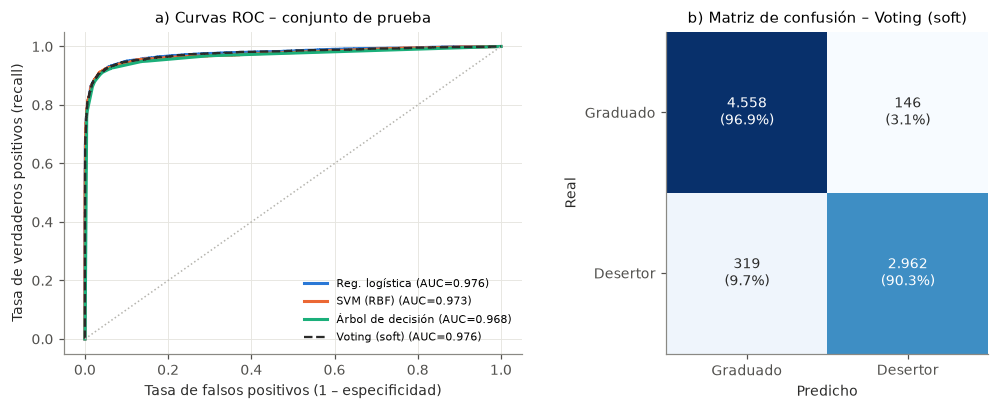

In [21]:
best_bin = max(["Reg. logística", "SVM (RBF)", "Árbol de decisión", "Voting (soft)"], key=lambda m: BIN[m]["F1-macro"])
RES["best_bin"] = best_bin
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
roc_cols = {"Reg. logística": C_BLUE, "SVM (RBF)": C_ORANGE, "Árbol de decisión": C_AQUA, "Voting (soft)": "#2b2b2a"}
for m, col in roc_cols.items():
    fpr, tpr, _ = roc_curve(yb_te, BIN_MODELS[m].predict_proba(Xb_te)[:, 1])
    ax.plot(fpr, tpr, color=col, lw=2 if m != "Voting (soft)" else 1.5, ls="-" if m != "Voting (soft)" else "--", label=f"{m} (AUC={BIN[m]['AUC']:.3f})")
ax.plot([0, 1], [0, 1], color="#b5b4ae", lw=1, ls=":")
ax.set_xlabel("Tasa de falsos positivos (1 – especificidad)"); ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title("a) Curvas ROC – conjunto de prueba"); ax.legend(loc="lower right", fontsize=7.5)
ax = axes[1]
cm = confusion_matrix(yb_te, BIN_MODELS[best_bin].predict(Xb_te))
ax.imshow(cm, cmap="Blues"); ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}".replace(",", ".") + f"\n({cm[i, j]/cm[i].sum():.1%})", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "#2b2b2a", fontsize=9)
ax.set_xticks([0, 1], ["Graduado", "Desertor"]); ax.set_yticks([0, 1], ["Graduado", "Desertor"])
ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title(f"b) Matriz de confusión – {best_bin}")
plt.tight_layout(); savefig("fig3_roc_cm_bin")
RES["cm_bin"] = cm.tolist()

### Curvas de complejidad (binaria)
F1-macro de entrenamiento y de validación (CV 5 folds) al variar el hiper-parámetro de complejidad, con los demás en su valor óptimo.
Para la SVM se usa la submuestra de 10 000 registros. En el árbol se agrega (punteada) la curva sin restricción de hoja.

89s


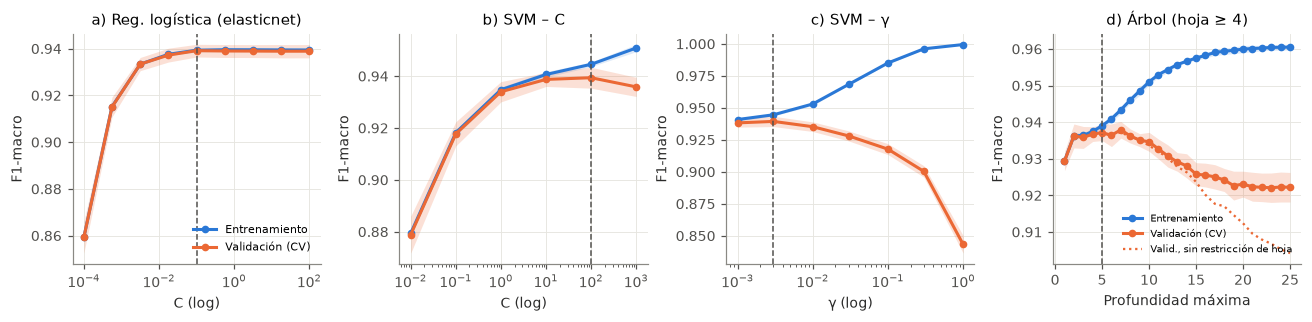

In [22]:
def vcurve(est, Xc, yc, pname, prange, scoring="f1_macro"):
    tr, va = validation_curve(est, Xc, yc, param_name=pname, param_range=prange, cv=cv5, scoring=scoring, n_jobs=N_JOBS)
    return tr.mean(1), tr.std(1), va.mean(1), va.std(1)

def plot_curve(ax, x, res, title, xlabel, best=None, logx=False, ylabel="F1-macro", ylim=None):
    trm, trs, vam, vas = res
    ax.plot(x, trm, color=C_BLUE, marker="o", ms=4, label="Entrenamiento")
    ax.fill_between(x, trm - trs, trm + trs, color=C_BLUE, alpha=.15, lw=0)
    ax.plot(x, vam, color=C_ORANGE, marker="o", ms=4, label="Validación (CV)")
    ax.fill_between(x, vam - vas, vam + vas, color=C_ORANGE, alpha=.2, lw=0)
    if best is not None: ax.axvline(best, color="#52514e", ls="--", lw=1)
    if logx: ax.set_xscale("log")
    if ylim: ax.set_ylim(*ylim)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

t = time.time()
curves_bin = {}
C_range = np.logspace(-4, 2, 9)
curves_bin["lr"] = (C_range, vcurve(gs_lr.best_estimator_, Xb_tr, yb_tr, "clf__C", C_range))
Cs_range = np.array([0.01, 0.1, 1, 10, 100, 1000])
curves_bin["svm_C"] = (Cs_range, vcurve(gs_svm.best_estimator_, Xs, ys, "clf__C", Cs_range))
g_range = np.array([0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0])
curves_bin["svm_gamma"] = (g_range, vcurve(gs_svm.best_estimator_, Xs, ys, "clf__gamma", g_range))
d_range = np.arange(1, 26)
dt_base = clone(gs_dt.best_estimator_)
curves_bin["dt"] = (d_range, vcurve(dt_base, Xb_tr, yb_tr, "clf__max_depth", d_range))
curves_bin["dt_leaf1"] = (d_range, vcurve(clone(dt_base).set_params(clf__min_samples_leaf=1, clf__min_samples_split=2), Xb_tr, yb_tr, "clf__max_depth", d_range))
print(f"{time.time()-t:.0f}s")

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
plot_curve(axes[0], *curves_bin["lr"], f"a) Reg. logística ({gs_lr.best_params_['clf__penalty']})", "C (log)", gs_lr.best_params_["clf__C"], logx=True)
plot_curve(axes[1], *curves_bin["svm_C"], "b) SVM – C", "C (log)", gs_svm.best_params_["clf__C"], logx=True)
plot_curve(axes[2], *curves_bin["svm_gamma"], "c) SVM – γ", "γ (log)", gs_svm.best_params_["clf__gamma"], logx=True)
best_depth = gs_dt.best_params_["clf__max_depth"] or d_range[-1]
plot_curve(axes[3], *curves_bin["dt"], f"d) Árbol (hoja ≥ {gs_dt.best_params_['clf__min_samples_leaf']})", "Profundidad máxima", best_depth)
if gs_dt.best_params_["clf__min_samples_leaf"] != 1 or gs_dt.best_params_["clf__min_samples_split"] != 2:
    axes[3].plot(d_range, curves_bin["dt_leaf1"][1][2], color=C_ORANGE, ls=":", lw=1.5, label="Valid., sin restricción de hoja")
    axes[3].legend(fontsize=6.5, loc="lower right")
axes[0].legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); savefig("fig4_complejidad_bin")
RES["curves_bin"] = {k: {"x": list(map(float, v[0])), "train": list(map(float, v[1][0])), "val": list(map(float, v[1][2]))} for k, v in curves_bin.items()}

### 3.6 Aplicación del modelo binario a los estudiantes "En curso"
Se usa la **regresión logística** (sus probabilidades están bien calibradas y su desempeño es equivalente al de los modelos más flexibles) para
estimar la probabilidad de deserción de los estudiantes en curso con sus datos del primer año. Como su desenlace se desconoce, este resultado
**no puede validarse** con estos datos: es una estimación de riesgo para orientar acciones de acompañamiento.

{'n': 9762, 'media': 0.4864035340699889, 'mediana': 0.4514706587515054, 'p_ge_05': 0.4715222290514239, 'p_ge_08': 0.26213890596189304, 'p_lt_02': 0.29020692481048965, 'dist': {'< 0,2 (bajo)': 0.2902, '0,2–0,5': 0.2383, '0,5–0,8': 0.2094, '≥ 0,8 (alto)': 0.2621}}


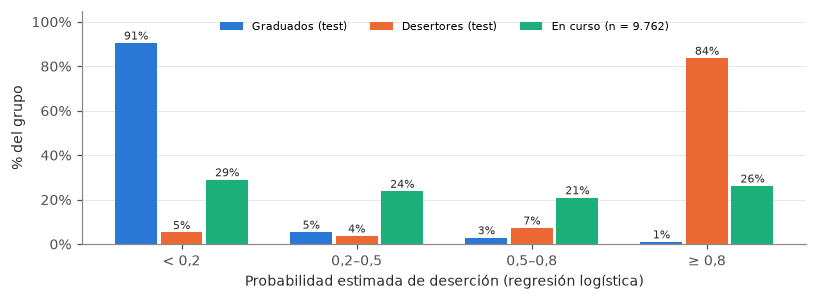

In [23]:
lr_bin = BIN_MODELS["Reg. logística"]
p_curso = lr_bin.predict_proba(df_curso[cat_bin + num_bin])[:, 1]
p_te = lr_bin.predict_proba(Xb_te)[:, 1]
cortes = [0, 0.2, 0.5, 0.8, 1.0001]
dist = pd.cut(pd.Series(p_curso), cortes, right=False, labels=["< 0,2 (bajo)", "0,2–0,5", "0,5–0,8", "≥ 0,8 (alto)"]).value_counts(normalize=True).sort_index()
RES["curso"] = {"n": int(len(p_curso)), "media": float(p_curso.mean()), "mediana": float(np.median(p_curso)),
                "p_ge_05": float((p_curso >= 0.5).mean()), "p_ge_08": float((p_curso >= 0.8).mean()), "p_lt_02": float((p_curso < 0.2).mean()),
                "dist": dist.round(4).to_dict()}
print(RES["curso"])

band_labels = ["< 0,2", "0,2–0,5", "0,5–0,8", "≥ 0,8"]
def bands(p): return pd.cut(pd.Series(p), cortes, right=False, labels=band_labels).value_counts(normalize=True).reindex(band_labels)
groups_b = {"Graduados (test)": bands(p_te[yb_te.values == 0]), "Desertores (test)": bands(p_te[yb_te.values == 1]),
            f"En curso (n = {len(p_curso):,})".replace(",", "."): bands(p_curso)}
RES["curso_bandas"] = {k: v.round(4).to_dict() for k, v in groups_b.items()}
fig, ax = plt.subplots(figsize=(7.5, 2.8))
xb = np.arange(4); w = 0.26
for k, ((lab, v), col) in enumerate(zip(groups_b.items(), [C_BLUE, C_ORANGE, C_AQUA])):
    ax.bar(xb + (k - 1) * w, v.values, width=w * 0.92, color=col, label=lab)
    for xi, val in zip(xb + (k - 1) * w, v.values):
        ax.text(xi, val + 0.015, f"{val:.0%}", ha="center", fontsize=7, color="#2b2b2a")
ax.set_xticks(xb, band_labels); ax.set_xlabel("Probabilidad estimada de deserción (regresión logística)")
ax.set_ylabel("% del grupo"); ax.set_ylim(0, 1.05); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.legend(fontsize=7.5, loc="upper center", ncol=3); ax.grid(axis="x", visible=False)
plt.tight_layout(); savefig("fig_en_curso")

## 3.7 Modelo explicativo: regresión logística con un conjunto reducido de predictores

Como la regresión logística alcanza el desempeño de los modelos flexibles, se la usa también para **explicar** la deserción. Para que sus
coeficientes sean interpretables hay que evitar la multicolinealidad (las variables académicas tienen ρ ≈ 0,8–0,9):
1. Se usa un conjunto reducido de predictores (macro-categorías y sin variables redundantes; p. ej., se excluye `es_deudor`, correlacionada con `es_moroso`).
2. El promedio de notas y la tasa de aprobación se estandarizan **con la media y el desvío del entrenamiento** y se promedian en un único
   **índice de rendimiento académico**.
3. Se elige la regularización L1 (Lasso) con **validación cruzada** (no con el test) y la regla de 1 error estándar.
4. Se estandarizan las variables continuas (sus OR corresponden a +1 desvío estándar); los indicadores 0/1 no se escalan.
5. Con las variables que retiene el Lasso se reajusta una regresión logística **sin penalización** (statsmodels) para obtener coeficientes,
   errores estándar, valores p e IC 95 %, y se revisa el **VIF**.

In [24]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

cat_exp = ["macro_categoria_estudios_maximos", "macro_categoria_estado_civil", "macro_categoria_carrera"]
num_exp_base = ["puntaje_ingreso", "edad_inscripcion", "tiene_necesidades_educativas_especiales", "es_masculino", "es_moroso",
                "es_becado", "es_estudiante_internacional", "promedio_cant_evaluaciones_semestres", "ingresos_familia_nivel"]
COLS_INDICE = ["promedio_notas_semestres", "ratio_aprobadas_inscritas"]
mu_idx, sd_idx = dfb.loc[Xb_tr.index, COLS_INDICE].mean(), dfb.loc[Xb_tr.index, COLS_INDICE].std()

def with_index(d):
    out = d[cat_exp + num_exp_base].copy()
    out["indice_rendimiento_academico"] = ((d[COLS_INDICE] - mu_idx) / sd_idx).mean(axis=1)
    return out

Xe_tr, Xe_te = with_index(dfb.loc[Xb_tr.index]), with_index(dfb.loc[Xb_te.index])
num_exp = num_exp_base + ["indice_rendimiento_academico"]
# Se estandarizan solo las variables continuas; los indicadores 0/1 quedan en su escala para que su OR se lea como "sí vs. no"
bin_exp = [c for c in num_exp if set(Xe_tr[c].unique()) <= {0, 1}]
cont_exp = [c for c in num_exp if c not in bin_exp]
prep_exp = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), cat_exp),
                              ("num", StandardScaler(), cont_exp), ("bin", "passthrough", bin_exp)]).fit(Xe_tr)
names_exp = [n.split("__", 1)[1] for n in prep_exp.get_feature_names_out()]
Ze_tr = pd.DataFrame(prep_exp.transform(Xe_tr), columns=names_exp, index=Xe_tr.index)
Ze_te = pd.DataFrame(prep_exp.transform(Xe_te), columns=names_exp, index=Xe_te.index)
RES["exp_ref_cats"] = {c: str(cats[0]) for c, cats in zip(cat_exp, prep_exp.named_transformers_["cat"].categories_)}
rho_exp = Xe_tr[num_exp].corr(method="spearman").abs().values
RES["exp_max_abs_rho"] = float(rho_exp[np.triu_indices(len(num_exp), 1)].max())
print("Referencias:", RES["exp_ref_cats"], "| máx |ρ| entre numéricas:", round(RES["exp_max_abs_rho"], 2))

Referencias: {'macro_categoria_estudios_maximos': 'Educación Básica', 'macro_categoria_estado_civil': 'Casado', 'macro_categoria_carrera': 'Administración y turismo'} | máx |ρ| entre numéricas: 0.39


In [25]:
t = time.time()
C_path = np.logspace(-4, 1, 16)
path_coef, f1_tr, f1_va, f1_va_se, path_nz = [], [], [], [], []
for C in C_path:
    m = LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=5000, random_state=SEED)
    tr_s, va_s = [], []
    for tr_i, va_i in cv5.split(Ze_tr, yb_tr):
        mm = clone(m).fit(Ze_tr.iloc[tr_i], yb_tr.iloc[tr_i])
        tr_s.append(f1_score(yb_tr.iloc[tr_i], mm.predict(Ze_tr.iloc[tr_i]), average="macro"))
        va_s.append(f1_score(yb_tr.iloc[va_i], mm.predict(Ze_tr.iloc[va_i]), average="macro"))
    m.fit(Ze_tr, yb_tr)
    path_coef.append(m.coef_[0]); f1_tr.append(np.mean(tr_s)); f1_va.append(np.mean(va_s)); f1_va_se.append(np.std(va_s) / np.sqrt(5))
    path_nz.append(int((m.coef_[0] != 0).sum()))
path_coef = pd.DataFrame(path_coef, index=C_path, columns=names_exp)
f1_tr, f1_va, f1_va_se = map(np.array, (f1_tr, f1_va, f1_va_se))
i_max = int(np.argmax(f1_va)); i_1se = int(np.argmax(f1_va >= f1_va[i_max] - f1_va_se[i_max]))
C_exp = float(C_path[i_1se])
lasso_exp = LogisticRegression(penalty="l1", solver="liblinear", C=C_exp, max_iter=5000, random_state=SEED).fit(Ze_tr, yb_tr)
sel = [n for n, b in zip(names_exp, lasso_exp.coef_[0]) if b != 0]
print(f"C elegido (1-SE) = {C_exp:.4g}: {len(sel)}/{len(names_exp)} variables | F1-macro CV {f1_va[i_1se]:.4f} (máx {f1_va[i_max]:.4f} con C={C_path[i_max]:.3g}) | {time.time()-t:.0f}s")

# Reajuste sin penalización (statsmodels) sobre las variables retenidas
logit = sm.Logit(yb_tr.values, sm.add_constant(Ze_tr[sel].values)).fit(disp=0, maxiter=200)
ci = logit.conf_int()
coef_tab = pd.DataFrame({"coef": logit.params[1:], "se": logit.bse[1:], "z": logit.tvalues[1:], "p": logit.pvalues[1:],
                         "ic_inf": ci[1:, 0], "ic_sup": ci[1:, 1]}, index=sel)
coef_tab["OR"] = np.exp(coef_tab["coef"])
coef_tab = coef_tab.reindex(coef_tab["coef"].abs().sort_values(ascending=False).index)
Zs_te = sm.add_constant(Ze_te[sel].values)
p_exp_te = logit.predict(Zs_te)
exp_test = {"F1-macro": f1_score(yb_te, (p_exp_te > 0.5).astype(int), average="macro"), "AUC": roc_auc_score(yb_te, p_exp_te),
            "Accuracy": accuracy_score(yb_te, (p_exp_te > 0.5).astype(int))}
vif = pd.Series([variance_inflation_factor(sm.add_constant(Ze_tr[sel].values), i + 1) for i in range(len(sel))], index=sel).sort_values(ascending=False)
RES["exp"] = {"C_grid": list(map(float, C_path)), "f1_tr": list(map(float, f1_tr)), "f1_va": list(map(float, f1_va)), "n_nonzero": path_nz,
              "C_1se": C_exp, "C_max": float(C_path[i_max]), "n_sel": len(sel), "n_total": len(names_exp), "test": exp_test,
              "intercepto": float(logit.params[0]), "coef": coef_tab.round(4).to_dict(orient="index"), "vif_max": float(vif.max()),
              "vif": vif.round(2).to_dict(), "cm_test": confusion_matrix(yb_te, (p_exp_te > 0.5).astype(int)).tolist()}
print("Test:", {k: round(v, 3) for k, v in exp_test.items()}, "| VIF máx:", round(vif.max(), 2))
coef_tab.round(3)

C elegido (1-SE) = 0.01: 10/20 variables | F1-macro CV 0.9251 (máx 0.9260 con C=0.0464) | 5s
Test: {'F1-macro': 0.925, 'AUC': 0.97, 'Accuracy': 0.928} | VIF máx: 2.18


,coef,se,z,p,ic_inf,ic_sup,OR
es_moroso,3.572,0.142,25.115,0.0,3.293,3.850,35.578
indice_rendimiento_academico,-3.294,0.044,-74.554,0.0,-3.380,-3.207,0.037
es_becado,-1.312,0.066,-19.734,0.0,-1.442,-1.181,0.269
promedio_cant_evaluaciones_semestres,0.799,0.029,27.964,0.0,0.743,0.855,2.223
macro_categoria_carrera_Salud,-0.748,0.072,-10.442,0.0,-0.888,-0.607,0.474
es_masculino,0.621,0.051,12.067,0.0,0.520,0.722,1.861
"macro_categoria_carrera_Comunicación, marketing y diseño",-0.452,0.060,-7.493,0.0,-0.571,-0.334,0.636
puntaje_ingreso,-0.229,0.025,-9.310,0.0,-0.277,-0.181,0.796
edad_inscripcion,0.094,0.025,3.801,0.0,0.046,0.143,1.099
ingresos_familia_nivel,-0.089,0.024,-3.759,0.0,-0.136,-0.043,0.914


### Curva de complejidad, trayectoria de coeficientes e importancia por permutación (modelo explicativo)

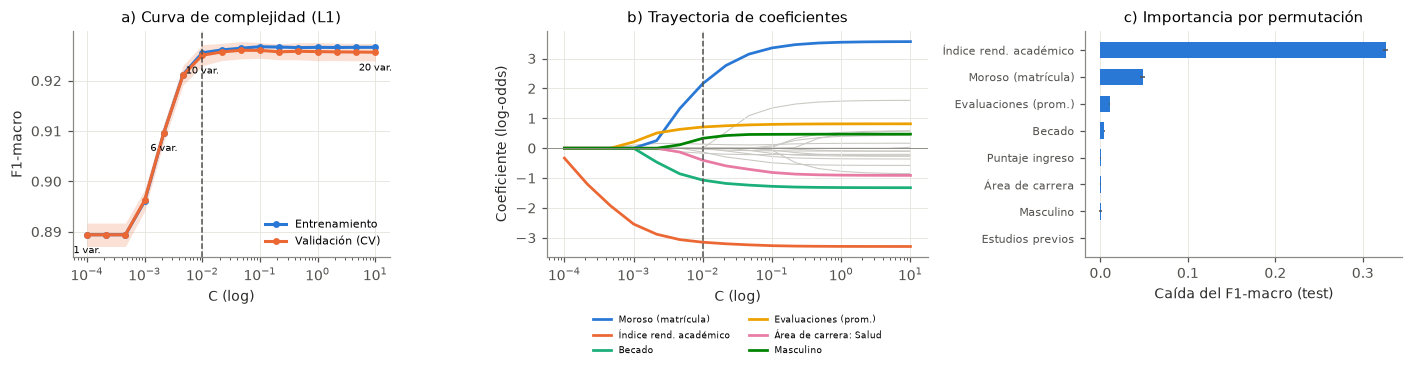

In [26]:
class ExpModel:
    """Envoltorio para permutar variables originales (índice incluido) y predecir con el logit reajustado."""
    def __init__(self, prep, sel, res): self.prep, self.sel, self.res, self.classes_ = prep, sel, res, np.array([0, 1])
    def fit(self, X, y): return self
    def predict_proba(self, X):
        Z = pd.DataFrame(self.prep.transform(X), columns=names_exp)[self.sel].values
        p = self.res.predict(sm.add_constant(Z, has_constant="add")); return np.column_stack([1 - p, p])
    def predict(self, X): return (self.predict_proba(X)[:, 1] > 0.5).astype(int)
exp_model = ExpModel(prep_exp, sel, logit)
# Importancia por permutación en test (manual: el modelo reajustado de statsmodels no es un estimador de sklearn)
rng = np.random.RandomState(SEED)
Xpi, ypi = Xe_te.reset_index(drop=True), yb_te.reset_index(drop=True)
base_f1 = f1_score(ypi, exp_model.predict(Xpi), average="macro")
perm = {}
for c in Xpi.columns:
    drops = []
    for _ in range(10):
        Xq = Xpi.copy(); Xq[c] = Xq[c].values[rng.permutation(len(Xq))]
        drops.append(base_f1 - f1_score(ypi, exp_model.predict(Xq), average="macro"))
    perm[c] = (np.mean(drops), np.std(drops))
imp_exp = pd.DataFrame(perm, index=["media", "sd"]).T.sort_values("media", ascending=False)
RES["exp_perm"] = imp_exp.round(4).to_dict(orient="index")

def nice_exp(n):
    rep = {"indice_rendimiento_academico": "Índice rend. académico", "es_moroso": "Moroso (matrícula)", "es_becado": "Becado",
           "es_masculino": "Masculino", "promedio_cant_evaluaciones_semestres": "Evaluaciones (prom.)", "puntaje_ingreso": "Puntaje ingreso",
           "edad_inscripcion": "Edad", "ingresos_familia_nivel": "Nivel ocup./ingresos familia", "es_estudiante_internacional": "Internacional",
           "tiene_necesidades_educativas_especiales": "Necesidades educ. esp.", "macro_categoria_carrera": "Área de carrera",
           "macro_categoria_estado_civil": "Estado civil", "macro_categoria_estudios_maximos": "Estudios previos"}
    for a, b in rep.items():
        if n.startswith(a): return b + n[len(a):].replace("_", ": ", 1)
    return n

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.2, 1]})
ax = axes[0]
ax.plot(C_path, f1_tr, color=C_BLUE, marker="o", ms=3.5, label="Entrenamiento")
ax.plot(C_path, f1_va, color=C_ORANGE, marker="o", ms=3.5, label="Validación (CV)")
ax.fill_between(C_path, f1_va - f1_va_se, f1_va + f1_va_se, color=C_ORANGE, alpha=.2, lw=0)
ax.axvline(C_exp, color="#52514e", ls="--", lw=1); ax.set_xscale("log")
for k in sorted({0, 4, i_1se, len(C_path) - 1}):
    ax.annotate(f"{path_nz[k]} var.", (C_path[k], f1_va[k]), textcoords="offset points", xytext=(0, -12), ha="center", fontsize=6.5)
ax.set_xlabel("C (log)"); ax.set_ylabel("F1-macro"); ax.set_title("a) Curva de complejidad (L1)"); ax.legend(fontsize=7, loc="lower right")
ax = axes[1]
top_vars = coef_tab.index[:6].tolist()
for v, col in zip(top_vars, [C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA, C_GREEN]):
    ax.plot(C_path, path_coef[v], color=col, lw=1.8, label=nice_exp(v))
for v in [v for v in names_exp if v not in top_vars]:
    ax.plot(C_path, path_coef[v], color="#c9c8c2", lw=0.7, zorder=0)
ax.axvline(C_exp, color="#52514e", ls="--", lw=1); ax.axhline(0, color="#8a8984", lw=0.6); ax.set_xscale("log")
ax.set_xlabel("C (log)"); ax.set_ylabel("Coeficiente (log-odds)"); ax.set_title("b) Trayectoria de coeficientes")
ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax = axes[2]; ti = imp_exp.head(8)[::-1]
ax.barh([nice_exp(c) for c in ti.index], ti["media"], xerr=ti["sd"], color=C_BLUE, height=0.6, error_kw={"lw": 1, "ecolor": "#52514e"})
ax.set_xlabel("Caída del F1-macro (test)"); ax.set_title("c) Importancia por permutación"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=7.5)
plt.tight_layout(); savefig("fig_explicativo")

### Dependencia parcial abierta por una variable categórica
Probabilidad predicha de deserción en función del índice de rendimiento académico, **fijando** cada valor de una variable categórica para todos
los estudiantes y promediando sobre el resto de sus atributos (dependencia parcial de dos variables). Muestra cómo cambia el efecto del rendimiento según la morosidad,
el sexo y el área de la carrera.

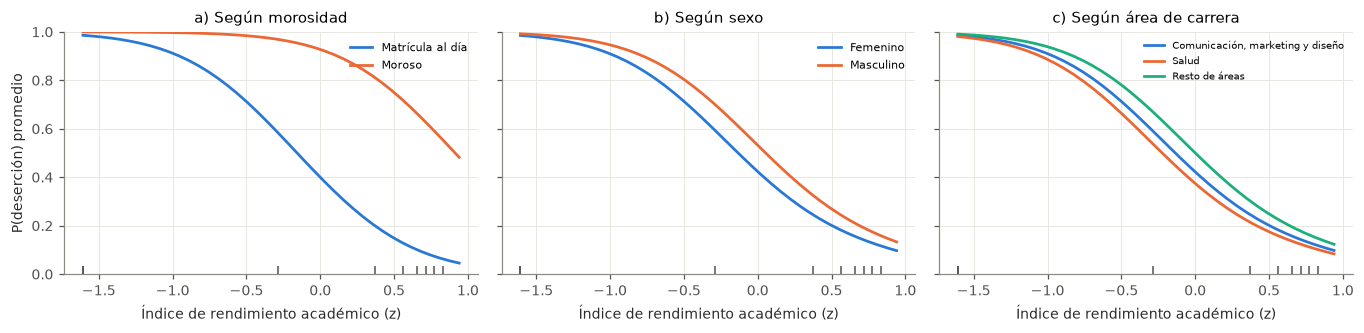

In [27]:
Xpd_e = Xe_te.sample(n=min(3000, len(Xe_te)), random_state=SEED)
grid_idx = np.linspace(np.percentile(Xe_tr["indice_rendimiento_academico"], 1), np.percentile(Xe_tr["indice_rendimiento_academico"], 99), 40)

def pd_by(col, values):
    out = {}
    for v in values:
        curve = []
        for g in grid_idx:
            Xg = Xpd_e.copy(); Xg[col] = v; Xg["indice_rendimiento_academico"] = g
            curve.append(exp_model.predict_proba(Xg)[:, 1].mean())
        out[v] = np.array(curve)
    return out

pd_moroso = pd_by("es_moroso", [0, 1])
pd_sexo = pd_by("es_masculino", [0, 1])
# solo las áreas con coeficiente propio en el modelo; el resto coincide con la categoría de referencia
ref_area = RES["exp_ref_cats"]["macro_categoria_carrera"]
areas_sel = [a for a in sorted(Xe_tr["macro_categoria_carrera"].unique()) if f"macro_categoria_carrera_{a}" in sel]
areas = areas_sel + [ref_area]
pd_area = pd_by("macro_categoria_carrera", areas)
RES["pdp_exp"] = {"grid": list(map(float, grid_idx)),
                  "moroso": {str(k): list(map(float, v)) for k, v in pd_moroso.items()},
                  "sexo": {str(k): list(map(float, v)) for k, v in pd_sexo.items()},
                  "area": {k: list(map(float, v)) for k, v in pd_area.items()}}

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.1), sharey=True)
deciles = np.percentile(Xe_tr["indice_rendimiento_academico"], np.arange(10, 100, 10))
for ax, (d, labels, title) in zip(axes, [(pd_moroso, {0: "Matrícula al día", 1: "Moroso"}, "a) Según morosidad"),
                                          (pd_sexo, {0: "Femenino", 1: "Masculino"}, "b) Según sexo"),
                                          (pd_area, {**{a: a for a in areas_sel}, ref_area: "Resto de áreas"}, "c) Según área de carrera")]):
    cols = [C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA, C_GREEN]
    for (k, curve), col in zip(d.items(), cols):
        ax.plot(grid_idx, curve, color=col, lw=1.8, label=labels[k])
    ax.plot(deciles, np.zeros(9) + 0.01, "|", color="#52514e", ms=8)
    ax.set_title(title); ax.set_xlabel("Índice de rendimiento académico (z)"); ax.set_ylim(0, 1)
    ax.legend(fontsize=6.5 if len(d) > 2 else 7.5, loc="upper right")
axes[0].set_ylabel("P(deserción) promedio")
plt.tight_layout(); savefig("fig_pdp_explicativo")

## 4. Clasificación multiclase: Desertor / En Curso / Graduado

Nueva partición estratificada **80/20** (semilla distinta). Selección de hiper-parámetros por CV 5 folds maximizando **F1-macro**
(promedio no ponderado del F1 de cada clase: no deja que la clase mayoritaria domine la métrica).

Estrategias multiclase: K-NN, árboles y sus ensambles son **intrínsecamente multiclase** (votan/estiman la proporción de cada clase en el vecindario u hoja);
AdaBoost usa SAMME (versión multiclase); XGBoost usa objetivo *softprob* (un árbol por clase y por iteración, equivalente a un esquema
*one-vs-rest* dentro del boosting). Como comparación se incluye una regresión logística multinomial y su versión *one-vs-rest*.

In [28]:
ym = df.target.copy()
classes = ["Desertor", "En Curso", "Graduado"]
ym_num = ym.map({c: i for i, c in enumerate(classes)})
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(X, ym_num, test_size=0.2, stratify=ym_num, random_state=SEED + 1)
print(Xm_tr.shape, Xm_te.shape); print(ym_tr.value_counts(normalize=True).round(3))

MC, MC_CV, MC_HP, MC_MODELS = {}, {}, {}, {}
def eval_mc(model, Xt, yt):
    p = model.predict(Xt); pr = model.predict_proba(Xt)
    f1c = f1_score(yt, p, average=None)
    return {"Accuracy": accuracy_score(yt, p), "Precision (macro)": precision_score(yt, p, average="macro"),
            "Recall (macro)": recall_score(yt, p, average="macro"), "F1 (macro)": f1_score(yt, p, average="macro"),
            "AUC (OvR macro)": roc_auc_score(yt, pr, multi_class="ovr", average="macro"),
            "F1 Desertor": f1c[0], "F1 En Curso": f1c[1], "F1 Graduado": f1c[2]}

def fit_mc(name, pipe, grid, Xfit=None, yfit=None):
    t = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv5, scoring="f1_macro", n_jobs=N_JOBS).fit(Xm_tr if Xfit is None else Xfit, ym_tr if yfit is None else yfit)
    MC_HP[name] = gs.best_params_; MC_CV[name] = cv_summary(gs)
    print(name, gs.best_params_, MC_CV[name], f"{time.time()-t:.0f}s")
    return gs

(39749, 25) (9938, 25)
target
2    0.473
0    0.330
1    0.196
Name: proportion, dtype: float64


### 4.1 K-NN
Hiper-parámetros: `k` ∈ {5 … 101}, ponderación (uniforme / por distancia), métrica (euclídea / Manhattan).

In [29]:
pipe_knn = Pipeline([("prep", make_prep()), ("clf", KNeighborsClassifier(n_jobs=1))])
gs_knn = fit_mc("K-NN", pipe_knn, {"clf__n_neighbors": [5, 11, 21, 41, 61, 101], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]})
MC_MODELS["K-NN"] = gs_knn.best_estimator_; MC["K-NN"] = eval_mc(gs_knn.best_estimator_, Xm_te, ym_te)

K-NN {'clf__n_neighbors': 21, 'clf__p': 1, 'clf__weights': 'uniform'} (0.7587691890717523, 0.004974759262888521) 65s


### 4.2 Árbol de decisión

In [30]:
gs_dtm = fit_mc("Árbol de decisión", Pipeline([("prep", make_prep()), ("clf", DecisionTreeClassifier(random_state=SEED))]),
                {"clf__max_depth": [4, 6, 8, 10, 12, 15, 20], "clf__min_samples_leaf": [1, 10, 50, 100],
                 "clf__criterion": ["gini", "entropy"], "clf__class_weight": [None, "balanced"]})
MC_MODELS["Árbol de decisión"] = gs_dtm.best_estimator_; MC["Árbol de decisión"] = eval_mc(gs_dtm.best_estimator_, Xm_te, ym_te)

Árbol de decisión {'clf__class_weight': None, 'clf__criterion': 'gini', 'clf__max_depth': 8, 'clf__min_samples_leaf': 1} (0.7751814899680806, 0.004775877490834927) 23s


### 4.3 Referencia lineal: regresión logística multinomial vs. one-vs-rest

In [31]:
from sklearn.multiclass import OneVsRestClassifier
gs_lrm = fit_mc("Reg. Log. multinomial", Pipeline([("prep", make_prep()), ("clf", LogisticRegression(max_iter=3000))]),
                {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]})
MC_MODELS["Reg. Log. multinomial"] = gs_lrm.best_estimator_; MC["Reg. Log. multinomial"] = eval_mc(gs_lrm.best_estimator_, Xm_te, ym_te)
lr_ovr = Pipeline([("prep", make_prep()), ("clf", OneVsRestClassifier(LogisticRegression(max_iter=3000, C=gs_lrm.best_params_["clf__C"], class_weight=gs_lrm.best_params_["clf__class_weight"])))]).fit(Xm_tr, ym_tr)
MC_MODELS["Reg. Log. OvR"] = lr_ovr; MC["Reg. Log. OvR"] = eval_mc(lr_ovr, Xm_te, ym_te)

Reg. Log. multinomial {'clf__C': 1, 'clf__class_weight': 'balanced'} (0.7809814957766972, 0.0052686122785280684) 7s


### 4.4 Bagging: Random Forest
Hiper-parámetros: `n_estimators` = 200, `max_depth` ∈ {12, 20, None}, `max_features` ∈ {sqrt, 0.3}, `min_samples_leaf` ∈ {1, 5}, `class_weight`.

In [32]:
gs_rf = fit_mc("Random Forest", Pipeline([("prep", make_prep()), ("clf", RandomForestClassifier(random_state=SEED, n_jobs=1))]),
               {"clf__n_estimators": [200], "clf__max_depth": [12, 20, None], "clf__max_features": ["sqrt", 0.3],
                "clf__min_samples_leaf": [1, 5], "clf__class_weight": [None, "balanced"]})
MC_MODELS["Random Forest"] = gs_rf.best_estimator_; MC["Random Forest"] = eval_mc(gs_rf.best_estimator_, Xm_te, ym_te)

Random Forest {'clf__class_weight': 'balanced', 'clf__max_depth': 20, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200} (0.7890100373031506, 0.005181579918993176) 114s


### 4.5 Boosting: AdaBoost (SAMME) y XGBoost
AdaBoost: 200 estimadores, `learning_rate` ∈ {0.1, 0.5, 1}, profundidad del árbol base ∈ {1, 2, 3}. XGBoost: `n_estimators` ∈ {200, 500}, `learning_rate` ∈ {0.05, 0.1}, `max_depth` ∈ {3, 5, 7}, `subsample` = `colsample_bytree` = 0.8.

In [33]:
gs_ada = fit_mc("AdaBoost", Pipeline([("prep", make_prep()), ("clf", AdaBoostClassifier(estimator=DecisionTreeClassifier(), random_state=SEED))]),
                {"clf__n_estimators": [200], "clf__learning_rate": [0.1, 0.5, 1.0], "clf__estimator__max_depth": [1, 2, 3]})
MC_MODELS["AdaBoost"] = gs_ada.best_estimator_; MC["AdaBoost"] = eval_mc(gs_ada.best_estimator_, Xm_te, ym_te)

AdaBoost {'clf__estimator__max_depth': 3, 'clf__learning_rate': 1.0, 'clf__n_estimators': 200} (0.7825832327875799, 0.004426425859469332) 62s


In [34]:
gs_xgb = fit_mc("XGBoost", Pipeline([("prep", make_prep()), ("clf", XGBClassifier(objective="multi:softprob", tree_method="hist", random_state=SEED, n_jobs=1, eval_metric="mlogloss"))]),
                {"clf__n_estimators": [200, 500], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [3, 5, 7], "clf__subsample": [0.8], "clf__colsample_bytree": [0.8]})
MC_MODELS["XGBoost"] = gs_xgb.best_estimator_; MC["XGBoost"] = eval_mc(gs_xgb.best_estimator_, Xm_te, ym_te)

XGBoost {'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 500, 'clf__subsample': 0.8} (0.7909192819400376, 0.005697710194296353) 30s


In [35]:
tab_mc = pd.DataFrame(MC).T
tab_mc["F1-macro CV (media ± sd)"] = [f"{MC_CV[m][0]:.3f} ± {MC_CV[m][1]:.3f}" if m in MC_CV else "–" for m in tab_mc.index]
tab_mc.round(3)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),AUC (OvR macro),F1 Desertor,F1 En Curso,F1 Graduado,F1-macro CV (media ± sd)
K-NN,0.800,0.773,0.751,0.758,0.909,0.825,0.582,0.867,0.759 ± 0.005
Árbol de decisión,0.808,0.774,0.757,0.763,0.914,0.841,0.574,0.876,0.775 ± 0.005
Reg. Log. multinomial,0.802,0.780,0.787,0.777,0.925,0.839,0.624,0.867,0.781 ± 0.005
Reg. Log. OvR,0.804,0.777,0.778,0.774,0.918,0.836,0.615,0.871,–
Random Forest,0.811,0.785,0.788,0.783,0.926,0.848,0.628,0.872,0.789 ± 0.005
AdaBoost,0.821,0.789,0.776,0.781,0.917,0.852,0.608,0.884,0.783 ± 0.004
XGBoost,0.828,0.798,0.785,0.791,0.934,0.857,0.626,0.889,0.791 ± 0.006


### 4.6 Comparación gráfica y matriz de confusión del mejor modelo

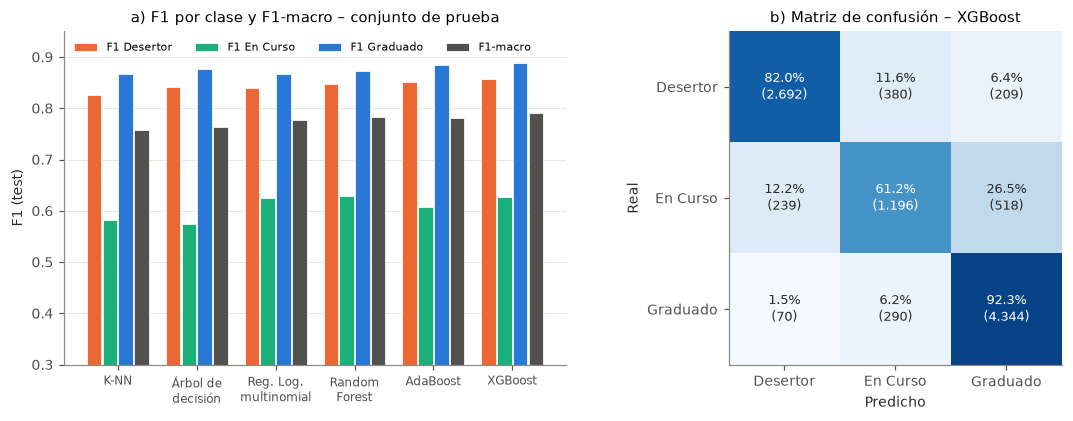

In [36]:
best_mc = max(MC, key=lambda m: MC[m]["F1 (macro)"])
RES["best_mc"] = best_mc
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]
models_plot = ["K-NN", "Árbol de decisión", "Reg. Log. multinomial", "Random Forest", "AdaBoost", "XGBoost"]
metrics_plot = ["F1 Desertor", "F1 En Curso", "F1 Graduado", "F1 (macro)"]
mcols = [C_ORANGE, C_AQUA, C_BLUE, "#52514e"]
w = 0.2; xx = np.arange(len(models_plot))
for k, (met, col) in enumerate(zip(metrics_plot, mcols)):
    vals = [MC[m][met] for m in models_plot]
    ax.bar(xx + (k - 1.5) * w, vals, width=w * 0.92, color=col, label=met.replace("F1 (macro)", "F1-macro"), edgecolor="white", linewidth=0.5)
ax.set_xticks(xx, [m.replace("Reg. Log. multinomial", "Reg. Log.\nmultinomial").replace("Árbol de decisión", "Árbol de\ndecisión").replace("Random Forest", "Random\nForest") for m in models_plot], fontsize=8)
ax.set_ylim(0.3, 0.95); ax.set_ylabel("F1 (test)"); ax.set_title("a) F1 por clase y F1-macro – conjunto de prueba")
ax.legend(ncol=4, fontsize=7.5, loc="upper left"); ax.grid(axis="x", visible=False)
ax = axes[1]
cm = confusion_matrix(ym_te, MC_MODELS[best_mc].predict(Xm_te))
cmn = cm / cm.sum(1, keepdims=True)
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cmn[i, j]:.1%}\n({cm[i, j]:,})".replace(",", "."), ha="center", va="center", color="white" if cmn[i, j] > .5 else "#2b2b2a", fontsize=8.5)
ax.set_xticks(range(3), classes); ax.set_yticks(range(3), classes); ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
ax.set_title(f"b) Matriz de confusión – {best_mc}")
plt.tight_layout(); savefig("fig5_mc_comp")
RES["cm_mc"] = cm.tolist()

### 4.7 Curvas de complejidad (multiclase)

In [37]:
t = time.time()
curves_mc = {}
k_range = np.array([1, 3, 5, 11, 21, 41, 61, 101, 151, 201])
knn_c = Pipeline([("prep", make_prep()), ("clf", KNeighborsClassifier(weights="uniform", p=gs_knn.best_params_["clf__p"]))])
# K-NN: la curva se calcula sobre una submuestra estratificada de 15 000 registros (evaluar el error de entrenamiento de K-NN exige
# predecir sobre todo el train, lo que es muy costoso)
Xk, _, yk, _ = train_test_split(Xm_tr, ym_tr, train_size=15000, stratify=ym_tr, random_state=SEED)
curves_mc["knn"] = (k_range, vcurve(knn_c, Xk, yk, "clf__n_neighbors", k_range, scoring="f1_macro"))
d_range2 = np.arange(1, 26)
curves_mc["dt"] = (d_range2, vcurve(gs_dtm.best_estimator_, Xm_tr, ym_tr, "clf__max_depth", d_range2, scoring="f1_macro"))
curves_mc["dt_leaf1"] = (d_range2, vcurve(clone(gs_dtm.best_estimator_).set_params(clf__min_samples_leaf=1), Xm_tr, ym_tr, "clf__max_depth", d_range2, scoring="f1_macro"))
rf_c = gs_rf.best_estimator_
rfd_range = np.array([2, 4, 6, 8, 10, 14, 18, 25, 35])
curves_mc["rf"] = (rfd_range, vcurve(Pipeline([("prep", make_prep()), ("clf", RandomForestClassifier(n_estimators=200, max_features=gs_rf.best_params_["clf__max_features"], class_weight=gs_rf.best_params_["clf__class_weight"], random_state=SEED, n_jobs=1))]),
                                      Xm_tr, ym_tr, "clf__max_depth", rfd_range, scoring="f1_macro"))
print(f"{time.time()-t:.0f}s")

97s


In [38]:
# XGBoost: curva de aprendizaje en función del número de árboles, usando un 20 % del train como validación
from sklearn.model_selection import train_test_split as tts
Xa, Xv, ya, yv = tts(Xm_tr, ym_tr, test_size=0.2, stratify=ym_tr, random_state=SEED)
pa = make_prep().fit(Xa)
xgb_params = {k.replace("clf__", ""): v for k, v in gs_xgb.best_params_.items() if k != "clf__n_estimators"}
curves_xgb = {}
for lr_ in [0.05, 0.3]:
    p_ = dict(xgb_params); p_["learning_rate"] = lr_
    xg = XGBClassifier(objective="multi:softprob", tree_method="hist", n_estimators=1000, random_state=SEED, n_jobs=N_JOBS, eval_metric="mlogloss", **p_)
    xg.fit(pa.transform(Xa), ya, eval_set=[(pa.transform(Xa), ya), (pa.transform(Xv), yv)], verbose=False)
    ev = xg.evals_result()
    curves_xgb[lr_] = (ev["validation_0"]["mlogloss"], ev["validation_1"]["mlogloss"])

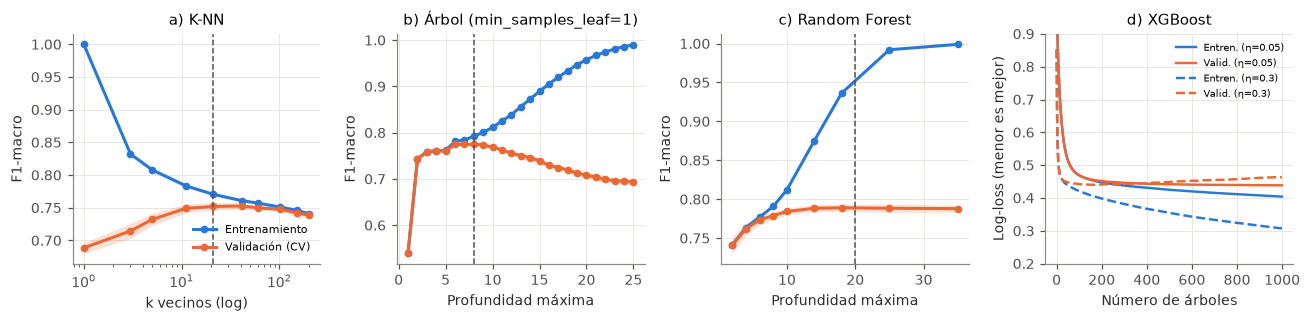

In [39]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
plot_curve(axes[0], *curves_mc["knn"], "a) K-NN", "k vecinos (log)", gs_knn.best_params_["clf__n_neighbors"], logx=True, ylabel="F1-macro")
plot_curve(axes[1], *curves_mc["dt"], f"b) Árbol (min_samples_leaf={gs_dtm.best_params_['clf__min_samples_leaf']})", "Profundidad máxima", gs_dtm.best_params_["clf__max_depth"], ylabel="F1-macro")
if gs_dtm.best_params_["clf__min_samples_leaf"] != 1:  # si el óptimo ya es 1, la curva punteada coincidiría con la llena
    axes[1].plot(curves_mc["dt_leaf1"][0], curves_mc["dt_leaf1"][1][2], color=C_ORANGE, ls=":", lw=1.5, label="Validación, min_samples_leaf=1")
    axes[1].plot(curves_mc["dt_leaf1"][0], curves_mc["dt_leaf1"][1][0], color=C_BLUE, ls=":", lw=1.5, label="Entren., min_samples_leaf=1")
    axes[1].legend(fontsize=6.5, loc="lower right")
best_rf_depth = gs_rf.best_params_["clf__max_depth"] or rfd_range[-1]
plot_curve(axes[2], *curves_mc["rf"], "c) Random Forest", "Profundidad máxima", best_rf_depth, ylabel="F1-macro")
ax = axes[3]
for lr_, ls in zip(curves_xgb, ["-", "--"]):
    tr_, va_ = curves_xgb[lr_]
    ax.plot(tr_, color=C_BLUE, ls=ls, lw=1.6, label=f"Entren. (η={lr_})")
    ax.plot(va_, color=C_ORANGE, ls=ls, lw=1.6, label=f"Valid. (η={lr_})")
ax.set_xlabel("Número de árboles"); ax.set_ylabel("Log-loss (menor es mejor)"); ax.set_title("d) XGBoost"); ax.set_ylim(0.2, 0.9)
ax.legend(fontsize=6.5)
axes[0].legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); savefig("fig6_complejidad_mc")
RES["curves_mc"] = {k: {"x": list(map(float, v[0])), "train": list(map(float, v[1][0])), "val": list(map(float, v[1][2]))} for k, v in curves_mc.items()}
RES["xgb_curve"] = {str(k): {"train_final": v[0][-1], "val_min": float(np.min(v[1])), "val_argmin": int(np.argmin(v[1])) + 1, "val_final": v[1][-1]} for k, v in curves_xgb.items()}

## 5. Importancia de atributos (multiclase)
Se usa **importancia por permutación** sobre el conjunto de prueba (caída del F1-macro al permutar cada variable original), que es
agnóstica al modelo y se calcula sobre las variables originales (antes del one-hot). Se compara con la importancia por ganancia de Random Forest.

In [40]:
t = time.time()
Xp, _, yp, _ = train_test_split(Xm_te, ym_te, train_size=5000, stratify=ym_te, random_state=SEED)
pi = permutation_importance(MC_MODELS[best_mc], Xp, yp, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=N_JOBS)
imp = pd.DataFrame({"media": pi.importances_mean, "sd": pi.importances_std}, index=Xp.columns).sort_values("media", ascending=False)
RES["perm_imp"] = imp.round(4).head(12).to_dict(orient="index")
print(f"{time.time()-t:.0f}s"); imp.head(12)

1s


,media,sd
Unidades_curriculares_2do_semestre_(aprobadas),0.173479,0.006773
Pago_de_matrícula_al_día,0.030473,0.002528
Unidades_curriculares_1er_semestre_(aprobadas),0.028444,0.004265
Nota_promedio_en_el_2do_semestre,0.020060,0.002943
Cantidad_de_evaluaciones_en_el_2do_semestre_,0.017587,0.002635
Unidades_curriculares_2do_semestre_(inscrito),0.010727,0.002661
Carrera,0.008751,0.001328
Poseedor_de_Beca,0.007456,0.001705
Edad_al_momento_de_la_inscripción,0.007182,0.002896
Cantidad_de_evaluaciones_en_el_1er_semestre,0.005036,0.002023


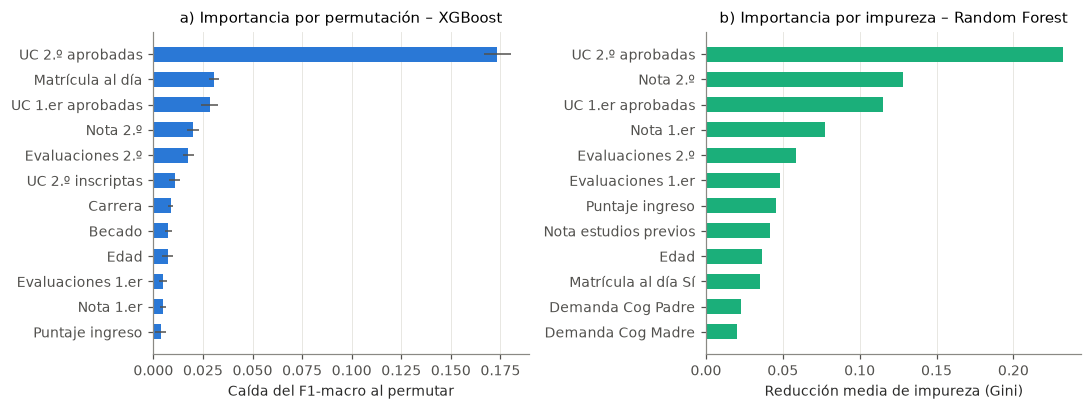

In [41]:
rf_m = MC_MODELS["Random Forest"]
rf_imp = pd.Series(rf_m.named_steps["clf"].feature_importances_, index=[i.split("__", 1)[1] for i in rf_m.named_steps["prep"].get_feature_names_out()]).sort_values(ascending=False)
RES["rf_imp_top"] = rf_imp.head(10).round(4).to_dict()

def short_name(c):
    rep = {"Unidades_curriculares_": "UC ", "_semestre": "", "Cantidad_de_evaluaciones_en_el_": "Evaluaciones ", "Nota_promedio_en_el_": "Nota ",
           "(aprobadas)": "aprobadas", "(inscrito)": "inscriptas", "Pago_de_matrícula_al_día": "Matrícula al día", "Edad_al_momento_de_la_inscripción": "Edad",
           "Puntaje_en_examen_de_ingreso": "Puntaje ingreso", "Cualificación_promedio_de_estudios_previos": "Nota estudios previos",
           "Poseedor_de_Beca": "Becado", "Tiene_deuda": "Tiene deuda", "modo_aplicacion": "Modo de acceso", "1er": "1.er", "2do": "2.º"}
    for a, b in rep.items(): c = c.replace(a, b)
    return c.replace("_", " ").strip()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]; top_i = imp.head(12)[::-1]
ax.barh([short_name(c) for c in top_i.index], top_i["media"], xerr=top_i["sd"], color=C_BLUE, height=0.6, error_kw={"lw": 1, "ecolor": "#52514e"})
ax.set_xlabel("Caída del F1-macro al permutar"); ax.set_title(f"a) Importancia por permutación – {best_mc}"); ax.grid(axis="y", visible=False)
ax = axes[1]; top_r = rf_imp.head(12)[::-1]
ax.barh([short_name(c) for c in top_r.index], top_r.values, color=C_AQUA, height=0.6)
ax.set_xlabel("Reducción media de impureza (Gini)"); ax.set_title("b) Importancia por impureza – Random Forest"); ax.grid(axis="y", visible=False)
plt.tight_layout(); savefig("fig7_importancia")

### 5.1 Importancia por permutación con variables correlacionadas
La importancia por permutación **subestima** las variables correlacionadas: si se permuta una de ellas, el modelo puede seguir usando la
información de su "gemela" (p. ej., UC aprobadas del 1.er y 2.º semestre, ρ ≈ 0,9), y ambas parecen poco importantes
([ver ejemplo de scikit-learn](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html)).
Siguiendo ese ejemplo: (1) se agrupan las variables con **clustering jerárquico sobre la correlación de Spearman** (distancia = 1 − |ρ|, enlace promedio)
y se cortan los grupos con |ρ| > 0,5; (2) se calcula la importancia **permutando a la vez todas las variables de cada grupo** (las mismas filas
para todo el grupo), lo que mide cuánto aporta el bloque de información en conjunto.

In [42]:
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

# Variables numéricas, ordinales y binarias (Sí/No) codificadas como números para medir la correlación de rangos
Xc = Xm_tr.copy()
for c in ord_cols:
    Xc[c] = Xc[c].map({v: i for i, v in enumerate(ord_levels[c])})
bin_like = [c for c in nom_cols if Xc[c].nunique() == 2]
for c in bin_like:
    Xc[c] = (Xc[c] == sorted(Xc[c].unique())[-1]).astype(int)   # "Sí", "Masculino", "Nocturna"
corr_cols = num_cols + ord_cols + bin_like
rho = Xc[corr_cols].corr(method="spearman").fillna(0).values
rho = (rho + rho.T) / 2; np.fill_diagonal(rho, 1)
dist = 1 - np.abs(rho)
hierarchy.set_link_color_palette([C_ORANGE, C_AQUA, C_BLUE, C_MAGENTA, C_YELLOW])
link = hierarchy.linkage(squareform(dist, checks=False), method="average")
cl = hierarchy.fcluster(link, t=0.5, criterion="distance")
groups = {}
for c, g in zip(corr_cols, cl):
    groups.setdefault(g, []).append(c)
groups = [g for g in groups.values()]
groups += [[c] for c in nom_cols if c not in bin_like]   # nominales multi-categoría: grupo propio
multi = [g for g in groups if len(g) > 1]
for g in multi: print(" + ".join(g))
RES["grupos_correlacionados"] = multi

Cualificación_promedio_de_estudios_previos + Puntaje_en_examen_de_ingreso
Unidades_curriculares_1er_semestre_(inscrito) + Unidades_curriculares_1er_semestre_(aprobadas) + Nota_promedio_en_el_1er_semestre + Unidades_curriculares_2do_semestre_(inscrito) + Unidades_curriculares_2do_semestre_(aprobadas) + Nota_promedio_en_el_2do_semestre
Cantidad_de_evaluaciones_en_el_1er_semestre + Cantidad_de_evaluaciones_en_el_2do_semestre_


In [43]:
def group_name(g):
    names = sorted({short_name(c) for c in g})
    if len(g) == 1: return names[0]
    if any("aprobadas" in n for n in names): return "Grupo académico (UC inscr./aprob. y notas)"
    if all("inscriptas" in n for n in names): return "UC inscriptas (ambos sem.)"
    if all("Evaluaciones" in n for n in names): return "Evaluaciones (ambos sem.)"
    if any("Puntaje" in n for n in names): return "Nota previa + puntaje ingreso"
    return " + ".join(names)

def grouped_permutation_importance(model, X, y, groups, n_repeats=5, seed=SEED):
    rng = np.random.RandomState(seed)
    base = f1_score(y, model.predict(X), average="macro")
    out = {}
    for g in groups:
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            idx = rng.permutation(len(Xp))
            Xp[g] = Xp[g].values[idx]        # mismas filas para todo el grupo: conserva la correlación interna
            drops.append(base - f1_score(y, model.predict(Xp), average="macro"))
        out[group_name(g)] = (np.mean(drops), np.std(drops), len(g))
    return pd.DataFrame(out, index=["media", "sd", "n_vars"]).T.sort_values("media", ascending=False)

t = time.time()
imp_g = grouped_permutation_importance(MC_MODELS[best_mc], Xp.reset_index(drop=True), yp.reset_index(drop=True), groups)
RES["perm_imp_grupos"] = imp_g.round(4).to_dict(orient="index")
print(f"{time.time()-t:.0f}s"); imp_g.head(12)

4s


,media,sd,n_vars
Grupo académico (UC inscr./aprob. y notas),0.338291,0.011108,6.0
Evaluaciones (ambos sem.),0.036547,0.006159,2.0
Matrícula al día,0.032493,0.003527,1.0
Carrera,0.009405,0.001664,1.0
Edad,0.006502,0.001017,1.0
Becado,0.006001,0.001154,1.0
Nota previa + puntaje ingreso,0.004026,0.001905,2.0
Tiene deuda,0.002044,0.000995,1.0
estado civil,0.001797,0.000662,1.0
Estudios máximos antes de la inscripción,0.000969,0.001065,1.0


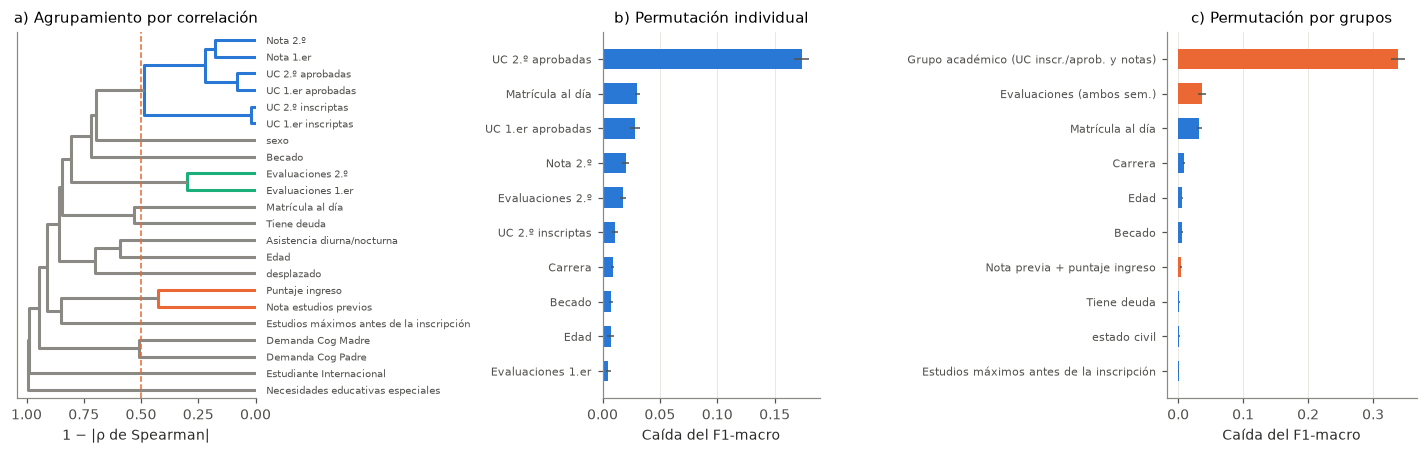

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.1, 1, 1.15]})
ax = axes[0]
dn = hierarchy.dendrogram(link, labels=[short_name(c) for c in corr_cols], orientation="left", ax=ax, color_threshold=0.5,
                          above_threshold_color="#8a8984", leaf_font_size=6.5)
ax.axvline(0.5, color=C_ORANGE, ls="--", lw=1); ax.set_xlabel("1 − |ρ de Spearman|"); ax.set_title("a) Agrupamiento por correlación"); ax.grid(False)
ax = axes[1]; top_i = imp.head(10)[::-1]
ax.barh([short_name(c) for c in top_i.index], top_i["media"], xerr=top_i["sd"], color=C_BLUE, height=0.6, error_kw={"lw": 1, "ecolor": "#52514e"})
ax.set_xlabel("Caída del F1-macro"); ax.set_title("b) Permutación individual"); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=7.5)
ax = axes[2]; top_g = imp_g.head(10)[::-1]
cols_g = [C_ORANGE if n > 1 else C_BLUE for n in top_g["n_vars"]]
ax.barh(top_g.index, top_g["media"], xerr=top_g["sd"], color=cols_g, height=0.6, error_kw={"lw": 1, "ecolor": "#52514e"})
ax.set_xlabel("Caída del F1-macro"); ax.set_title("c) Permutación por grupos"); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=7.5)
plt.tight_layout(); savefig("fig7_importancia_grupos")

### 5.2 Dependencia parcial (PDP)
La dependencia parcial muestra cómo cambia la **probabilidad predicha** de cada clase al variar un atributo, promediando sobre los valores
observados del resto. Supone que el atributo puede variar independientemente de los demás: con variables muy correlacionadas (las académicas)
la curva extrapola a combinaciones poco realistas y debe leerse como el efecto "marginal" que aprendió el modelo, no como un efecto causal.

2s


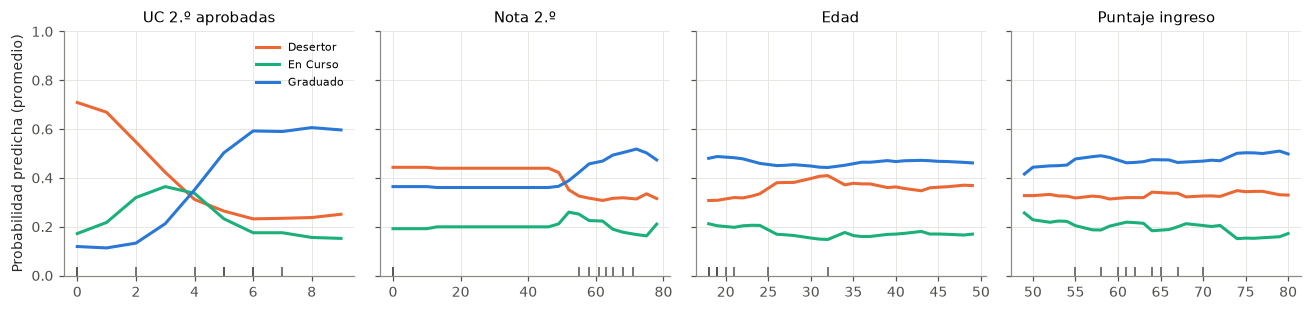

In [45]:
from sklearn.inspection import partial_dependence
pdp_feats = ["Unidades_curriculares_2do_semestre_(aprobadas)", "Nota_promedio_en_el_2do_semestre",
             "Edad_al_momento_de_la_inscripción", "Puntaje_en_examen_de_ingreso"]
Xpd = Xp.reset_index(drop=True).iloc[:2000].astype({f: float for f in pdp_feats})  # PDP exige columnas float
t = time.time()
PDP = {}
for f in pdp_feats:
    lo, hi = np.percentile(Xm_tr[f], [1, 99])
    grid = np.unique(np.round(np.linspace(lo, hi, 25)))
    pdr = partial_dependence(MC_MODELS[best_mc], Xpd, [f], kind="average", custom_values={f: grid})
    PDP[f] = (pdr["grid_values"][0], pdr["average"])   # average: (n_clases, n_grid)
print(f"{time.time()-t:.0f}s")
RES["pdp"] = {f: {"x": list(map(float, v[0])), **{classes[k]: list(map(float, v[1][k])) for k in range(3)}} for f, v in PDP.items()}

fig, axes = plt.subplots(1, 4, figsize=(12, 2.9), sharey=True)
for ax, f in zip(axes, pdp_feats):
    xg, av = PDP[f]
    for k, cname in enumerate(classes):
        ax.plot(xg, av[k], color=CLASS_COLORS[cname], lw=2, label=cname)
    # distribución observada (deciles) como marcas en el eje x
    ax.plot(np.percentile(Xm_tr[f], np.arange(10, 100, 10)), np.zeros(9) + 0.01, "|", color="#52514e", ms=8)
    ax.set_title(short_name(f)); ax.set_ylim(0, 1)
axes[0].set_ylabel("Probabilidad predicha (promedio)"); axes[0].legend(fontsize=7.5, loc="upper right")
plt.tight_layout(); savefig("fig9_pdp")

## 6. Tablas resumen de hiper-parámetros y exportación de resultados

In [46]:
def fmt_hp(d): return {k.replace("clf__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in d.items()}
hp_rows = [("Binaria", m, fmt_hp(v)) for m, v in BIN_HP.items()] + [("Multiclase", m, fmt_hp(v)) for m, v in MC_HP.items()]
pd.DataFrame(hp_rows, columns=["Esquema", "Modelo", "Hiper-parámetros elegidos"])

,Esquema,Modelo,Hiper-parámetros elegidos
0,Binaria,Reg. logística,"{'C': 0.1, 'l1_ratio': 0.5, 'penalty': 'elasti..."
1,Binaria,SVM (RBF),"{'C': 100, 'gamma': 0.003}"
2,Binaria,Árbol de decisión,"{'criterion': 'gini', 'max_depth': 5, 'min_sam..."
3,Multiclase,K-NN,"{'n_neighbors': 21, 'p': 1, 'weights': 'uniform'}"
4,Multiclase,Árbol de decisión,"{'class_weight': None, 'criterion': 'gini', 'm..."
5,Multiclase,Reg. Log. multinomial,"{'C': 1, 'class_weight': 'balanced'}"
6,Multiclase,Random Forest,"{'class_weight': 'balanced', 'max_depth': 20, ..."
7,Multiclase,AdaBoost,"{'estimator__max_depth': 3, 'learning_rate': 1..."
8,Multiclase,XGBoost,"{'colsample_bytree': 0.8, 'learning_rate': 0.1..."


In [47]:
RES.update({"BIN": BIN, "BIN_CV": BIN_CV, "BIN_HP": {k: fmt_hp(v) for k, v in BIN_HP.items()},
            "MC": MC, "MC_CV": MC_CV, "MC_HP": {k: fmt_hp(v) for k, v in MC_HP.items()},
            "n_train_bin": len(Xb_tr), "n_test_bin": len(Xb_te), "n_train_mc": len(Xm_tr), "n_test_mc": len(Xm_te)})
print(classification_report(ym_te, MC_MODELS[best_mc].predict(Xm_te), target_names=classes, digits=3))
with open("resultados.json", "w", encoding="utf-8") as f:
    json.dump(RES, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))

              precision    recall  f1-score   support

    Desertor      0.897     0.820     0.857      3281
    En Curso      0.641     0.612     0.626      1953
    Graduado      0.857     0.923     0.889      4704

    accuracy                          0.828      9938
   macro avg      0.798     0.785     0.791      9938
weighted avg      0.828     0.828     0.827      9938

